# Stage 0 -- forecast-error experiments: gate and procedure

Implements `experiments.md`'s stage 0: the ESS forecast-error experiment package
(`src/experiments/`), run against its required validation gate, with every step shown
explicitly -- not just the final numbers.

**Research question** (`experiments.md` section 1): Baldick's SOC-based design lets the
ESS submit technical data and an end-of-horizon value; the ISO optimises the state of
charge. The conventional ("current") design only accepts a price/quantity curve per
hour, built from a forecast. Under perfect foresight the two are *provably* equivalent
(`verify_equivalence.py`, `verify_price_based.py` -- already validated, unmodified).
**Open question**: how much welfare is lost when the curve is built from a forecast
instead of the true price, and what drives it?

## Important caveat, read first

`pilot/pilot2.py` and `pilot/multi_ess.py` -- the reference implementation that defines
the actual "pilot day case" (thermal fleet, demand, ESS data) and produced
`experiments.md`'s published stage-0 target numbers (11.1% of V = \$875, V =
\$7,866.6/day, etc.) -- are **not present in this repository** (confirmed by search, not
just misplaced). This was raised with the user directly; the agreed path forward:

- `day_case()` reuses `verify_equivalence.baldick_case` -- the single-bus system from
  Baldick (2026) Sec. 4.7 that `verify_equivalence.py`, `verify_price_based.py` and
  `numerical_check.py` already validate the SOC/CD equivalence on.
- Stage 0 here checks the gate's **structural** properties (B_star reproduces dSW≈0, no
  simultaneous charge/discharge, dSW never negative, the forecast model's own sampling
  statistics) rather than matching the specific published numbers, which this repo has
  no way to reproduce or verify against.

Everything below is reproducible from what's actually in this repository.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from experiments import benchmark, bids, cases, config, forecasts, market, metrics, realtime, runner, welfare
from experiments.config import BidRule, ErrorModel, RealTime, RunSettings

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
np.set_printoptions(suppress=True)

In [2]:
# Plot conventions: one colour per physical quantity, the same in every figure of this notebook.
COL = dict(renewable="#5aa469", thermal="#8a8f98", discharge="#eb6834", charge="#2a78d6", shed="#9b1c1c",
           price="#1f2328", forecast="#7b4bb7", bench="#9aa0a6", bound="#5b6068", bad="#c0392b")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e3e5e8", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "legend.frameon": False, "font.size": 9, "axes.titlesize": 10})


def interval_labels(T, dT):
    return [f"{int(t * dT):02d}-{int((t + 1) * dT):02d}h" for t in range(T)]


def block_names(case):
    """One name per generator block, in case['gens'] order (= the row order of every q array)."""
    return ["renewable" if cost == 0 else f"thermal ({cost:g} $/MWh)"
            for G in case["gens"] for cost, _ in G["blocks"]]


def block_caps(case):
    """(n_blocks, T) MW capacity of every generator block."""
    return np.array([qb for G in case["gens"] for _, qb in G["blocks"]], dtype=float)


def soc_path(S, p, g, dT):
    """SOC at the end of each interval from (A8): s_t = gamma*s_{t-1} + dT*(a*p_t - b*g_t).
    No limits applied -- used to show where a schedule WOULD take the battery."""
    s, out = S["s0"], []
    for pt, gt in zip(p, g):
        s = S["g"] * s + dT * (S["a"] * pt - S["b"] * gt)
        out.append(s)
    return np.array(out)


def set_interval_axis(ax, T, dT):
    ax.set_xticks(np.arange(1, T + 1))
    ax.set_xticklabels(interval_labels(T, dT), fontsize=7.5)
    ax.set_xlim(0.4, T + 0.6)


def energy_balance(ax, case, q, p, g, shed, title):
    """Supply stacked above zero (renewable, thermal, ESS discharge, shed), ESS charge below zero,
    demand as a black bar. Above-zero total = demand + charge."""
    T = case["T"]
    t = np.arange(1, T + 1)
    kw = dict(width=0.7, edgecolor="white", linewidth=0.8)
    bottom = np.zeros(T)
    for name, row in zip(block_names(case), q):
        ax.bar(t, row, bottom=bottom, color=COL["renewable" if name == "renewable" else "thermal"], label=name, **kw)
        bottom += row
    ax.bar(t, g, bottom=bottom, color=COL["discharge"], label="ESS discharge", **kw)
    bottom += g
    if np.any(shed > 1e-9):
        ax.bar(t, shed, bottom=bottom, color=COL["shed"], label="load shed", **kw)
    ax.bar(t, -np.asarray(p), color=COL["charge"], label="ESS charge (shown < 0)", **kw)
    ax.hlines(case["D"][0], t - 0.42, t + 0.42, color=COL["price"], lw=2.2, label="demand")
    ax.axhline(0, color=COL["bound"], lw=0.8)
    top = max(bottom.max(), case["D"][0].max())
    ax.set_ylim(min(-1.15 * np.max(p), -0.05 * top), 1.55 * top)   # headroom for the legend
    ax.set_ylabel("MW")
    ax.set_title(title)
    set_interval_axis(ax, T, case["dT"])
    ax.legend(fontsize=7, ncol=3, loc="upper left")


def soc_axis(ax, S, T, dT):
    ax.axhspan(S["smin"], S["smax"], color="#eef4fb", zorder=0, label="feasible SOC")
    ax.axhline(S["smax"], color=COL["bound"], ls=":", lw=1)
    ax.axhline(S["smin"], color=COL["bound"], ls=":", lw=1)
    ax.set_ylabel("SOC (MWh)")
    ax.set_xticks(np.arange(0.5, T + 1.5))
    ax.set_xticklabels([f"{int(k * dT)}h" for k in range(T + 1)])
    ax.set_xlim(0.4, T + 0.6)


def plot_soc(ax, S, s, **kw):
    """SOC is a state at interval boundaries: x = 0.5 (start, s0), 1.5 (end of interval 1), ..."""
    ax.plot(np.arange(0.5, len(s) + 1), np.r_[S["s0"], s], marker="o", ms=4, **kw)

## 1. The test system (`day_case`)

Baldick (2026) Sec. 4.7's base case, as returned by `cases.day_case()` -- a plain Python `dict` from which
every LP is assembled on the fly. Below it is shown as three tables: what changes per interval, the
generator blocks, and the battery's technical data.

In [3]:
case = cases.day_case()
S = case["ess"][0]
T, dT = case["T"], case["dT"]
hours = pd.Index(interval_labels(T, dT), name="interval")
names, caps = block_names(case), block_caps(case)

# (a) everything that varies per interval
system_df = pd.DataFrame({"demand D (MW)": case["D"][0]}, index=hours)
for name, cap in zip(names, caps):
    system_df[f"{name} capacity (MW)"] = cap
system_df["total generation capacity (MW)"] = caps.sum(axis=0)
system_df["margin without ESS (MW)"] = caps.sum(axis=0) - case["D"][0]
print(f"Time: T = {T} intervals of dT = {dT} h.  Single bus (N = {case['N']}), no lines, no elastic demand.")
display(system_df)

# (b) generator blocks (cost and ramp limits are constant over the day)
gen_rows = []
for i, G in enumerate(case["gens"]):
    for cost, qb in G["blocks"]:
        gen_rows.append({"generator": i, "bus": G["n"], "marginal cost ($/MWh)": cost,
                         "capacity min-max (MW)": f"{min(qb):g} - {max(qb):g}",
                         "ramp up (MW/h)": G["Ru"], "ramp down (MW/h)": G["Rd"]})
gens_df = pd.DataFrame(gen_rows, index=pd.Index(names, name="block"))
display(gens_df)

# (c) the battery
ess_meaning = [
    ("alpha", "a", "-", "charge efficiency: MWh stored per MWh bought"),
    ("beta", "b", "-", "MWh removed from storage per MWh sold"),
    ("gamma", "g", "-", "share of SOC kept from one interval to the next (self-discharge)"),
    ("epsilon", "eps", "$/MWh", "degradation cost per MWh charged"),
    ("zeta", "zet", "$/MWh", "degradation cost per MWh discharged"),
    ("s_min", "smin", "MWh", "lowest SOC"),
    ("s_max", "smax", "MWh", "highest SOC"),
    ("s_0", "s0", "MWh", "SOC at the start of the day"),
    ("p_bar", "pbar", "MW", "max charge power (non-binding here)"),
    ("g_bar", "gbar", "MW", "max discharge power (non-binding here)"),
    ("w", "w", "$/MWh", "terminal value of each MWh left at the end of the day"),
]
ess_df = pd.DataFrame([dict(symbol=sym, key=key, value=S[key], unit=unit, meaning=m) for sym, key, unit, m in ess_meaning]
                      ).set_index("symbol")
display(ess_df)

Time: T = 6 intervals of dT = 4.0 h.  Single bus (N = 1), no lines, no elastic demand.


,demand D (MW),renewable capacity (MW),thermal (50 $/MWh) capacity (MW),total generation capacity (MW),margin without ESS (MW)
interval,,,,,
00-04h,100.0,200.0,100.0,300.0,200.0
04-08h,200.0,100.0,100.0,200.0,0.0
08-12h,300.0,500.0,100.0,600.0,300.0
12-16h,300.0,500.0,100.0,600.0,300.0
16-20h,200.0,25.0,100.0,125.0,-75.0
20-24h,100.0,0.0,100.0,100.0,0.0


,generator,bus,marginal cost ($/MWh),capacity min-max (MW),ramp up (MW/h),ramp down (MW/h)
block,,,,,,
renewable,0,0,0.0,0 - 500,1000000.0,1000000.0
thermal (50 $/MWh),1,0,50.0,100 - 100,1000000.0,1000000.0


,key,value,unit,meaning
symbol,,,,
alpha,a,0.9,-,charge efficiency: MWh stored per MWh bought
beta,b,1.0,-,MWh removed from storage per MWh sold
gamma,g,1.0,-,share of SOC kept from one interval to the nex...
epsilon,eps,1.0,$/MWh,degradation cost per MWh charged
zeta,zet,1.0,$/MWh,degradation cost per MWh discharged
s_min,smin,0.0,MWh,lowest SOC
s_max,smax,800.0,MWh,highest SOC
s_0,s0,0.0,MWh,SOC at the start of the day
p_bar,pbar,1000.0,MW,max charge power (non-binding here)


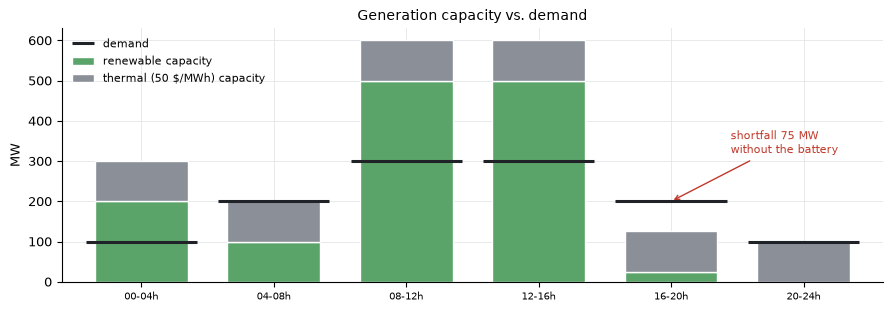

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.2))
t = np.arange(1, T + 1)
bottom = np.zeros(T)
for name, cap in zip(names, caps):
    ax.bar(t, cap, bottom=bottom, width=0.7, edgecolor="white",
           color=COL["renewable" if name == "renewable" else "thermal"], label=f"{name} capacity")
    bottom += cap
ax.hlines(case["D"][0], t - 0.42, t + 0.42, color=COL["price"], lw=2.2, label="demand")
short = np.where(caps.sum(axis=0) < case["D"][0])[0]
for k in short:
    ax.annotate(f"shortfall {case['D'][0][k] - caps[:, k].sum():.0f} MW\nwithout the battery",
                (k + 1, case["D"][0][k]), xytext=(k + 1.45, case["D"][0][k] + 120), fontsize=8,
                arrowprops=dict(arrowstyle="->", color=COL["bad"]), color=COL["bad"])
set_interval_axis(ax, T, dT)
ax.set_ylabel("MW"); ax.set_title("Generation capacity vs. demand")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

## 2. The benchmark: Baldick's own SOC-based solve

`benchmark.solve_benchmark` runs `verify_equivalence.build(case, "SOC")`, reads
`lambda_star` and every ESS's own duals (`pi`, `nu_up`, `nu_lo`) and schedule, and adds
`SW_noESS` -- the same system with the ESS removed and load shedding allowed at VOLL
(implemented as an ordinary, very expensive supply block: see
`benchmark.with_shedding_generator`).

In [5]:
bench = benchmark.solve_benchmark(case)

print(f"SW_star   = ${bench.SW_star:>12,.2f}")
print(f"SW_noESS  = ${bench.SW_noESS:>12,.2f}")
print(f"V         = ${bench.V:>12,.2f}   (storage value = SW_star - SW_noESS)")


SW_star   = $  -19,448.89
SW_noESS  = $ -360,000.00
V         = $  340,551.11   (storage value = SW_star - SW_noESS)


**Why is `V` so large relative to `SW_star`?** Without the battery, hour 5 needs 200
MW but only 25 MW of renewable + 100 MW of thermal (125 MW) is available -- a genuine
75 MW shortfall, shed at VOLL=\$1000/MWh for 4h = \$300,000. The battery exists
*precisely* to cover that gap in this example, so removing it doesn't just raise costs
modestly, it creates an outright reliability problem. `V` is large because of that, not
because of a bug -- worth keeping in mind when reading the `dSW_pct` figures below:
this system's `V` is reliability-dominated, not a pure arbitrage value.

In [6]:
# Full benchmark dispatch: generators, battery, prices and the battery's duals
bench_df = pd.DataFrame({"demand (MW)": case["D"][0]}, index=hours)
for name, q, cap in zip(names, bench.q_star, caps):
    bench_df[f"{name} (MW)"] = q.round(2)
    if name == "renewable":
        bench_df["renewable curtailed (MW)"] = (cap - q).round(2)
bench_df["ESS charge p* (MW)"] = bench.p_star[0].round(2)
bench_df["ESS discharge g* (MW)"] = bench.g_star[0].round(2)
bench_df["SOC s* end (MWh)"] = bench.s_star[0].round(2)
bench_df["lambda* ($/MWh)"] = bench.lam_star[0].round(3)
bench_df["pi* ($/MWh)"] = bench.pi_star[0].round(3)
bench_df["nu_up* ($/MWh)"] = bench.nuU_star[0].round(3)
bench_df["nu_lo* ($/MWh)"] = bench.nuL_star[0].round(3)
bench_df["SOC limit binding"] = np.where(bench.nuU_star[0] > 1e-9, "upper (s_max)",
                                         np.where(bench.nuL_star[0] > 1e-9, "lower (s_min)", ""))
display(bench_df)

# the welfare function used for every realised outcome, evaluated at Baldick's own dispatch, reproduces SW_star
w_bench = welfare.realised_welfare(case, bench.q_star, [S], bench.p_star, bench.g_star, [bench.s_star[0][-1]],
                                   np.zeros(T), np.zeros(T), psi=0.0, voll=RealTime().voll)
assert abs(w_bench.SW_real - bench.SW_star) < 1e-6
print(f"realised_welfare at the benchmark dispatch = {w_bench.SW_real:,.2f} = SW_star  (same yardstick for every draw)")

,demand (MW),renewable (MW),renewable curtailed (MW),thermal (50 $/MWh) (MW),ESS charge p* (MW),ESS discharge g* (MW),SOC s* end (MWh),lambda* ($/MWh),pi* ($/MWh),nu_up* ($/MWh),nu_lo* ($/MWh),SOC limit binding
interval,,,,,,,,,,,,
00-04h,100.0,200.00,0.00,0.0,100.00,0.0,360.0,43.1,49.000,0.000,0.000,
04-08h,200.0,100.00,0.00,10.0,0.00,90.0,-0.0,50.0,1.111,0.000,47.889,lower (s_min)
08-12h,300.0,500.00,0.00,0.0,200.00,0.0,720.0,0.0,1.111,0.000,0.000,
12-16h,300.0,322.22,177.78,0.0,22.22,0.0,800.0,0.0,49.000,47.889,0.000,upper (s_max)
16-20h,200.0,25.00,0.00,0.0,0.00,175.0,100.0,50.0,49.000,0.000,0.000,
20-24h,100.0,0.00,0.00,75.0,0.00,25.0,-0.0,50.0,40.000,0.000,9.000,lower (s_min)


realised_welfare at the benchmark dispatch = -19,448.89 = SW_star  (same yardstick for every draw)


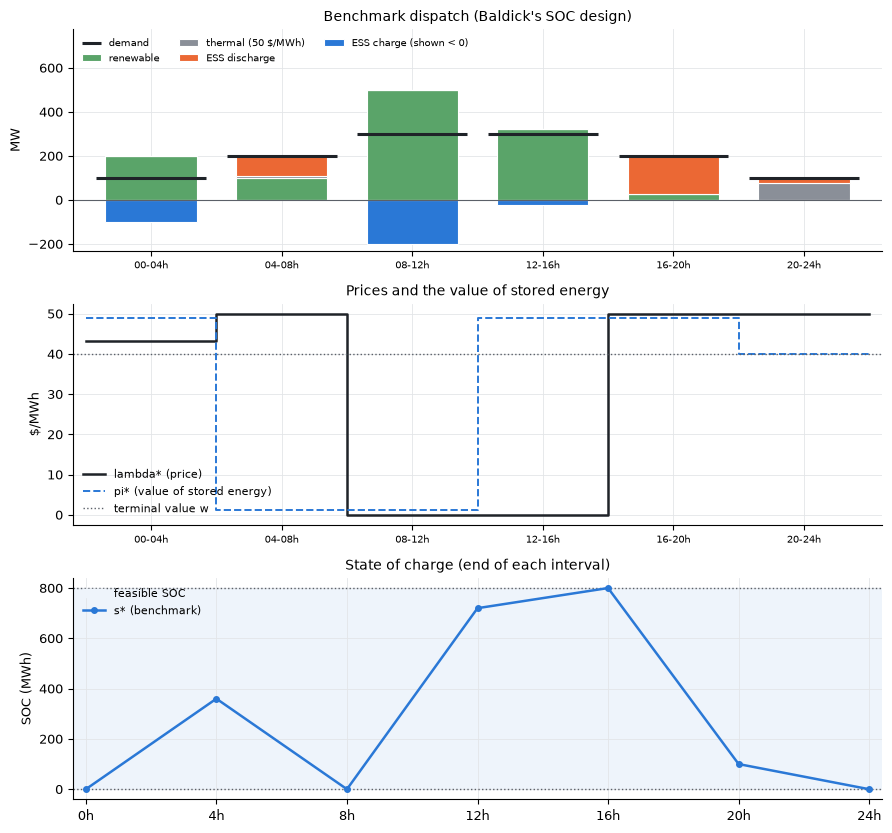

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(9, 8.4), sharex=False)
energy_balance(axes[0], case, bench.q_star, bench.p_star[0], bench.g_star[0], np.zeros(T),
               "Benchmark dispatch (Baldick's SOC design)")

ax = axes[1]
ax.step(np.r_[t, T + 1] - 0.5, np.r_[bench.lam_star[0], bench.lam_star[0][-1]], where="post",
        color=COL["price"], lw=1.8, label="lambda* (price)")
ax.step(np.r_[t, T + 1] - 0.5, np.r_[bench.pi_star[0], bench.pi_star[0][-1]], where="post",
        color=COL["charge"], lw=1.4, ls="--", label="pi* (value of stored energy)")
ax.axhline(S["w"], color=COL["bound"], ls=":", lw=1, label="terminal value w")
set_interval_axis(ax, T, dT); ax.set_ylabel("$/MWh"); ax.set_title("Prices and the value of stored energy")
ax.legend(fontsize=8, loc="lower left")

ax = axes[2]
soc_axis(ax, S, T, dT)
plot_soc(ax, S, bench.s_star[0], color=COL["charge"], lw=1.8, label="s* (benchmark)")
ax.set_title("State of charge (end of each interval)"); ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

How to read it: the battery charges in the cheap intervals (00-04h on surplus renewables, 08-16h when the
price is 0 and renewables are curtailed), reaches `s_max` at the end of 12-16h (`nu_up*` > 0 there), and
discharges in the expensive ones -- covering the 16-20h shortfall. Where a SOC limit binds, `pi*` jumps:
the value of stored energy differs across the binding hour.

## 3. How the forecast `lambda_hat` is built from `lambda*`

`forecasts.forecast_prices` (experiments.md 4.2), for battery `e` and interval `t`, with `lam_bar = mean(lambda*)`:

$$\hat\lambda_{e,t} = \lambda^\star_t + \underbrace{\tfrac{\text{bias\_pct}}{100}\,\bar\lambda}_{\text{bias}} + \sigma\, z_{e,t},
\qquad z_{e,t} = \sqrt{\omega}\,\chi_t + \sqrt{1-\omega}\,\eta_{e,t}$$

$\chi$ (common to every battery) and $\eta_e$ (this battery only) are independent AR(1) paths with unit
variance: $x_1 \sim N(0,1)$, $x_t = \rho\,x_{t-1} + \sqrt{1-\rho^2}\,w_t$. With one battery, $\omega$ has no
effect.

**Choose the draw here.** The same settings are used in Sections 4 and 7, so the whole chain -- forecast, bid,
market, real time -- is shown for one reproducible seed. (The experiment runs derive their seeds from
`RunSettings.seed`, which uses Python's `hash()` and changes between sessions; here the seed is passed
explicitly, so it is stable.)

In [8]:
SEED = 1005        # <- any integer. 1005 was a catastrophic draw before the price floor (set PRICE_FLOOR = None)
SIGMA = 1.0        # $/MWh, absolute error std (stage 0 uses 1, 2, 5, 10, 20)
RHO = 0.0          # autocorrelation of the error from one interval to the next
BIAS_PCT = 0.0     # systematic error, % of mean(lambda*)
PRICE_FLOOR = 0.0  # $/MWh, lowest price the forecast may predict; None = no floor (docs/model_structure.pdf, 6.5)
RULE = "prelimit"  # which point of the multiplier polyhedron the bid uses ("prelimit" or "solver")
PSI = 10.0         # real-time redispatch premium, $/MWh
KAPPA = BidRule().tie_break_reward  # $/MWh, self-schedule tie-breaker: most throughput among optimal plans; 0 = off

error = ErrorModel(sigma_abs=SIGMA, rho=RHO, bias_pct=BIAS_PCT, price_floor=PRICE_FLOOR)

In [9]:
lam_star = bench.lam_star[0]
lam_bar = lam_star.mean()
sigma = error.sigma_value(lam_bar)
bias = error.bias_pct / 100.0 * lam_bar

# exactly the steps of forecasts.forecast_prices, same RNG calls in the same order
rng = np.random.default_rng(SEED)
chi = forecasts.ar1_unit_variance(T, error.rho, rng)   # common component (drawn even with one battery)
eta = forecasts.ar1_unit_variance(T, error.rho, rng)   # this battery's own component
z = np.sqrt(error.omega) * chi + np.sqrt(1.0 - error.omega) * eta
lam_raw = lam_star + bias + sigma * z                  # before the price floor
lam_hat = lam_raw if error.price_floor is None else np.maximum(lam_raw, error.price_floor)

# the library function gives the same vector
assert np.allclose(lam_hat, forecasts.forecast_prices(lam_star, error, 1, T, np.random.default_rng(SEED))[0])

fc_df = pd.DataFrame({
    "lambda* ($/MWh)": lam_star, "chi (common)": chi, "eta (own)": eta, "z": z,
    "sigma*z ($/MWh)": sigma * z, "bias ($/MWh)": bias, "before floor ($/MWh)": lam_raw,
    "lambda_hat ($/MWh)": lam_hat, "floor binds": np.where(lam_hat > lam_raw, "yes", ""),
    "error lambda_hat - lambda*": lam_hat - lam_star,
}, index=hours).round(3)
print(f"mean(lambda*) = {lam_bar:.3f} $/MWh,  sigma = {sigma:.3f} $/MWh,  bias = {bias:.3f} $/MWh,  "
      f"rho = {error.rho},  omega = {error.omega},  price floor = {error.price_floor}")
display(fc_df)

mean(lambda*) = 32.183 $/MWh,  sigma = 1.000 $/MWh,  bias = 0.000 $/MWh,  rho = 0.0,  omega = 0.0,  price floor = 0.0


,lambda* ($/MWh),chi (common),eta (own),z,sigma*z ($/MWh),bias ($/MWh),before floor ($/MWh),lambda_hat ($/MWh),floor binds,error lambda_hat - lambda*
interval,,,,,,,,,,
00-04h,43.1,-0.711,-0.522,-0.522,-0.522,0.0,42.578,42.578,,-0.522
04-08h,50.0,-0.182,1.965,1.965,1.965,0.0,51.965,51.965,,1.965
08-12h,0.0,-0.578,-2.007,-2.007,-2.007,0.0,-2.007,0.000,yes,-0.000
12-16h,0.0,-0.157,-0.636,-0.636,-0.636,0.0,-0.636,0.000,yes,0.000
16-20h,50.0,1.023,0.828,0.828,0.828,0.0,50.828,50.828,,0.828
20-24h,50.0,-0.628,-0.516,-0.516,-0.516,0.0,49.484,49.484,,-0.516


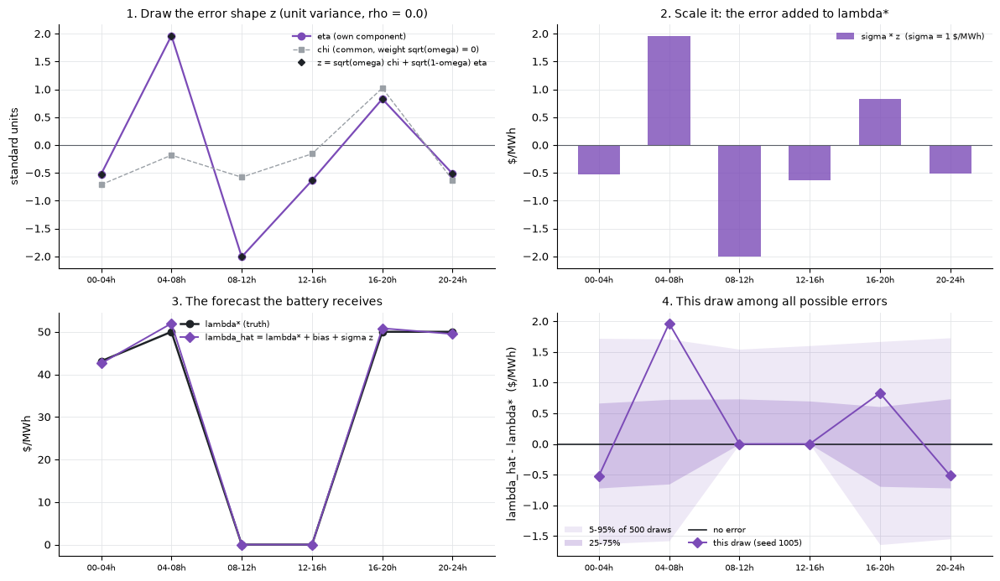

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

ax = axes[0, 0]
ax.axhline(0, color=COL["bound"], lw=0.8)
ax.plot(t, eta, "o-", color=COL["forecast"], lw=1.6, label="eta (own component)")
ax.plot(t, chi, "s--", color=COL["bench"], lw=1, ms=4, label=f"chi (common, weight sqrt(omega) = {np.sqrt(error.omega):g})")
ax.plot(t, z, "D", color=COL["price"], ms=4, label="z = sqrt(omega) chi + sqrt(1-omega) eta")
set_interval_axis(ax, T, dT); ax.set_ylabel("standard units")
ax.set_title(f"1. Draw the error shape z (unit variance, rho = {error.rho})"); ax.legend(fontsize=7.5)

ax = axes[0, 1]
ax.axhline(0, color=COL["bound"], lw=0.8)
ax.bar(t, sigma * z, 0.6, color=COL["forecast"], alpha=0.8, label=f"sigma * z  (sigma = {sigma:g} $/MWh)")
if bias:
    ax.bar(t, np.full(T, bias), 0.6, bottom=sigma * z, color=COL["bench"], label=f"bias = {bias:.2f} $/MWh")
set_interval_axis(ax, T, dT); ax.set_ylabel("$/MWh")
ax.set_title("2. Scale it: the error added to lambda*"); ax.legend(fontsize=7.5)

ax = axes[1, 0]
ax.plot(t, lam_star, "o-", color=COL["price"], lw=1.8, label="lambda* (truth)")
ax.plot(t, lam_hat, "D-", color=COL["forecast"], lw=1.4, label="lambda_hat = lambda* + bias + sigma z")
set_interval_axis(ax, T, dT); ax.set_ylabel("$/MWh")
ax.set_title("3. The forecast the battery receives"); ax.legend(fontsize=7.5)

# where this draw's error sits among many draws with the same settings
ax = axes[1, 1]
many = np.array([forecasts.forecast_prices(lam_star, error, 1, T, np.random.default_rng(10_000 + k))[0]
                 for k in range(500)]) - lam_star
lo5, lo25, hi75, hi95 = np.percentile(many, [5, 25, 75, 95], axis=0)
ax.fill_between(t, lo5, hi95, color=COL["forecast"], alpha=0.12, lw=0, label="5-95% of 500 draws")
ax.fill_between(t, lo25, hi75, color=COL["forecast"], alpha=0.25, lw=0, label="25-75%")
ax.axhline(0, color=COL["price"], lw=1.2, label="no error")
ax.plot(t, lam_hat - lam_star, "D-", color=COL["forecast"], lw=1.4, label=f"this draw (seed {SEED})")
set_interval_axis(ax, T, dT); ax.set_ylabel("lambda_hat - lambda*  ($/MWh)")
ax.set_title("4. This draw among all possible errors"); ax.legend(fontsize=7.5, ncol=2)
fig.tight_layout(); plt.show()

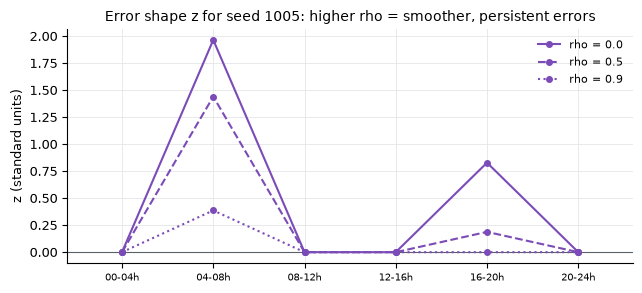

In [11]:
# What rho does to the SHAPE of the error: same seed, three autocorrelations
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.axhline(0, color=COL["bound"], lw=0.8)
for r, ls in [(0.0, "-"), (0.5, "--"), (0.9, ":")]:
    zr = forecasts.forecast_prices(np.zeros(T), ErrorModel(sigma_abs=1.0, rho=r), 1, T, np.random.default_rng(SEED))[0]
    ax.plot(t, zr, ls, marker="o", ms=4, color=COL["forecast"], lw=1.5, label=f"rho = {r}")
set_interval_axis(ax, T, dT); ax.set_ylabel("z (standard units)")
ax.set_title(f"Error shape z for seed {SEED}: higher rho = smoother, persistent errors")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

**Bias: the same day forecast with more and with less bias.** The bias shifts the whole forecast up or down
by `bias_pct`% of mean(lambda*) before the random error is added (and before the floor). Two independent seeds,
same `sigma`, `rho` and price floor as above; each forecast is also pushed through the full pipeline (bid ->
day-ahead -> real time) to show its welfare loss. Note the asymmetry the floor creates: a positive bias lifts
the forecast in the free intervals (lambda* = 0), a negative one is stopped at the floor there.

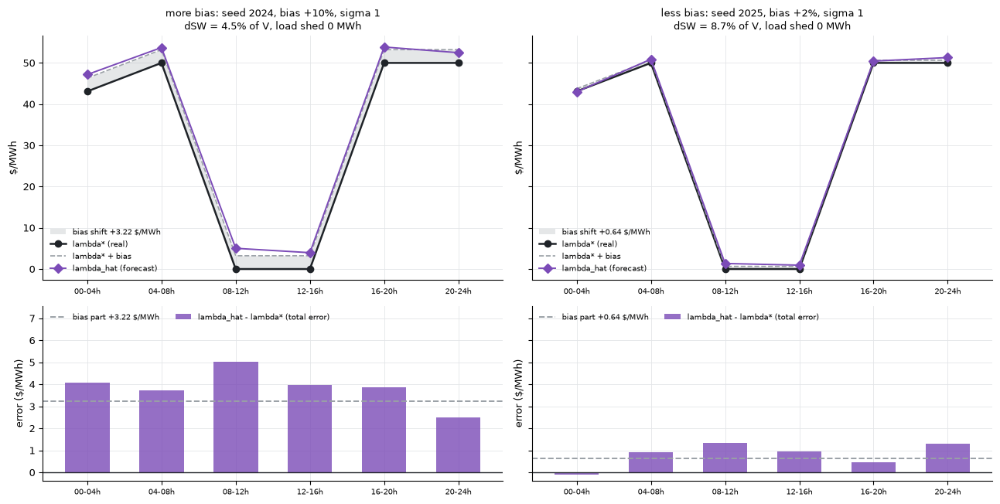

real  more bias                       less bias                     
         lambda* lambda_hat lambda_hat - lambda* lambda_hat lambda_hat - lambda*
interval                                                                        
00-04h      43.1     47.180                4.080     42.984               -0.116
04-08h      50.0     53.728                3.728     50.911                0.911
08-12h       0.0      5.029                5.029      1.345                1.345
12-16h       0.0      3.969                3.969      0.936                0.936
16-20h      50.0     53.858                3.858     50.446                0.446
20-24h      50.0     52.487                2.487     51.302                1.302

In [12]:
BIAS_CASES = [("more bias", 2024, 10.0),    # (label, seed, bias_pct) -- edit freely
              ("less bias", 2025, 2.0)]

fig, axes = plt.subplots(2, len(BIAS_CASES), figsize=(13, 6.6), sharey="row",
                         gridspec_kw=dict(height_ratios=[1.4, 1]))
bias_rows = {}
for j, (label, seed, bpct) in enumerate(BIAS_CASES):
    ax, ax_err = axes[0, j], axes[1, j]
    err_b = ErrorModel(sigma_abs=SIGMA, rho=RHO, bias_pct=bpct, price_floor=PRICE_FLOOR)
    lh = forecasts.forecast_prices(lam_star, err_b, 1, T, np.random.default_rng(seed))[0]
    shift = err_b.bias_pct / 100.0 * lam_bar
    blk = bids.quantity_blocks(bids.bid_fcst(S, lh, T, dT, RULE, KAPPA), S, BidRule().delta, full_capacity=False)
    out = runner.evaluate_blocks(case, [blk], RealTime(psi=PSI))
    loss = metrics.dsw_pct(metrics.dsw(bench.SW_star, out.welfare.SW_real), bench.V)

    ax.fill_between(t, lam_star, lam_star + shift, step=None, color=COL["bench"], alpha=0.25, lw=0,
                    label=f"bias shift {shift:+.2f} $/MWh")
    ax.plot(t, lam_star, "o-", color=COL["price"], lw=1.8, label="lambda* (real)")
    ax.plot(t, lam_star + shift, "--", color=COL["bench"], lw=1.2, label="lambda* + bias")
    ax.plot(t, lh, "D-", color=COL["forecast"], lw=1.4, label="lambda_hat (forecast)")
    set_interval_axis(ax, T, dT); ax.set_ylabel("$/MWh")
    ax.set_title(f"{label}: seed {seed}, bias {bpct:+g}%, sigma {SIGMA:g}\n"
                 f"dSW = {loss:.1f}% of V, load shed {dT * out.shed_rt.sum():.0f} MWh", fontsize=9.5)
    ax.legend(fontsize=7.5, loc="lower left")

    # the same forecast as an error: bias (constant) + random part
    ax_err.axhline(0, color=COL["price"], lw=1)
    ax_err.bar(t, lh - lam_star, 0.6, color=COL["forecast"], alpha=0.8, label="lambda_hat - lambda* (total error)")
    ax_err.axhline(shift, color=COL["bench"], ls="--", lw=1.4, label=f"bias part {shift:+.2f} $/MWh")
    set_interval_axis(ax_err, T, dT); ax_err.set_ylabel("error ($/MWh)")
    ax_err.legend(fontsize=7.5, loc="upper left", ncol=2)
    bias_rows[(label, "lambda_hat")] = lh
    bias_rows[(label, "lambda_hat - lambda*")] = lh - lam_star
lo, hi = axes[1, 0].get_ylim()
axes[1, 0].set_ylim(lo, hi + 0.4 * (hi - lo))   # headroom for the legends (row shares y)
fig.tight_layout(); plt.show()

bias_df = pd.DataFrame(bias_rows, index=hours)
bias_df.insert(0, ("real", "lambda*"), lam_star)
display(bias_df.round(3))

**Where the price floor matters: the free intervals.** In 08-16h the true price is exactly 0 (renewables are
curtailed). Without a floor the forecast there would be negative half the time, whatever `sigma` is. The floor
clips those values to 0 -- in this test case it is the only place it binds -- so the error there is
max(0, sigma*z): never negative, 0 half the time, +0.4 sigma on average.

In [13]:
free = np.where(np.isclose(lam_star, 0.0, atol=1e-9))[0]   # intervals where lambda* = 0
print("free intervals (lambda* = 0):", [hours[k] for k in free])
for k in free:
    clipped = " -> clipped to the floor" if lam_hat[k] > lam_raw[k] else ""
    print(f"  {hours[k]}: before floor {lam_raw[k]:+.3f}, lambda_hat = {lam_hat[k]:+.3f} $/MWh{clipped}")

free intervals (lambda* = 0): ['08-12h', '12-16h']
  08-12h: before floor -2.007, lambda_hat = +0.000 $/MWh -> clipped to the floor
  12-16h: before floor -0.636, lambda_hat = +0.000 $/MWh -> clipped to the floor


## 4. Bid families (`experiments.md` section 4.3)

Four ways a battery turns technical data (and, for three of them, price information) into a curve:

| Family | Prices from | Quantity plan | Role |
|---|---|---|---|
| `B_star` | `lambda*`'s own duals | the benchmark schedule itself | must give dSW=0 (gate) |
| `B_star_p` | `lambda*` | own self-schedule at `lambda*` | quantity-information loss |
| `B_fcst` | forecast `lambda_hat` (Section 3) | own self-schedule at `lambda_hat` | the main experiment |
| `B_priv` | technical data only (`w`, `gamma`) | full capacity | lower bound |

`B_star_p` and `B_fcst` need two choices, because the self-schedule's optimum is often not unique:

- **which plan** (quantities): when several plans give the battery the same profit, it takes the one with the
  most throughput `sum(p+g)` -- the self-schedule objective carries a tie-breaking term
  `-kappa*dT*sum(p+g)`, `kappa = BidRule.tie_break_reward` (`KAPPA` in Section 3's settings). The term is
  never part of welfare, and `kappa` is kept small enough that the plan stays optimal for the true profit
  (`bids.self_schedule`, `docs/model_structure.pdf` M3);
- **which dual multiplier** (prices): `prelimit` (sequential projection) or `solver` (the vertex minimising `sum(pi)`).

**How to read the chart.** Each interval's bid is a band: the battery **buys** when the price is at or below
its charge bid `u` (bottom edge, blue) and **sells** when the price is at or above its offer `c` (top edge,
orange); in between it does nothing. The dot is the true price `lambda*`: below the band = charge, above =
discharge, inside = idle, on an edge = the battery is the marginal unit.

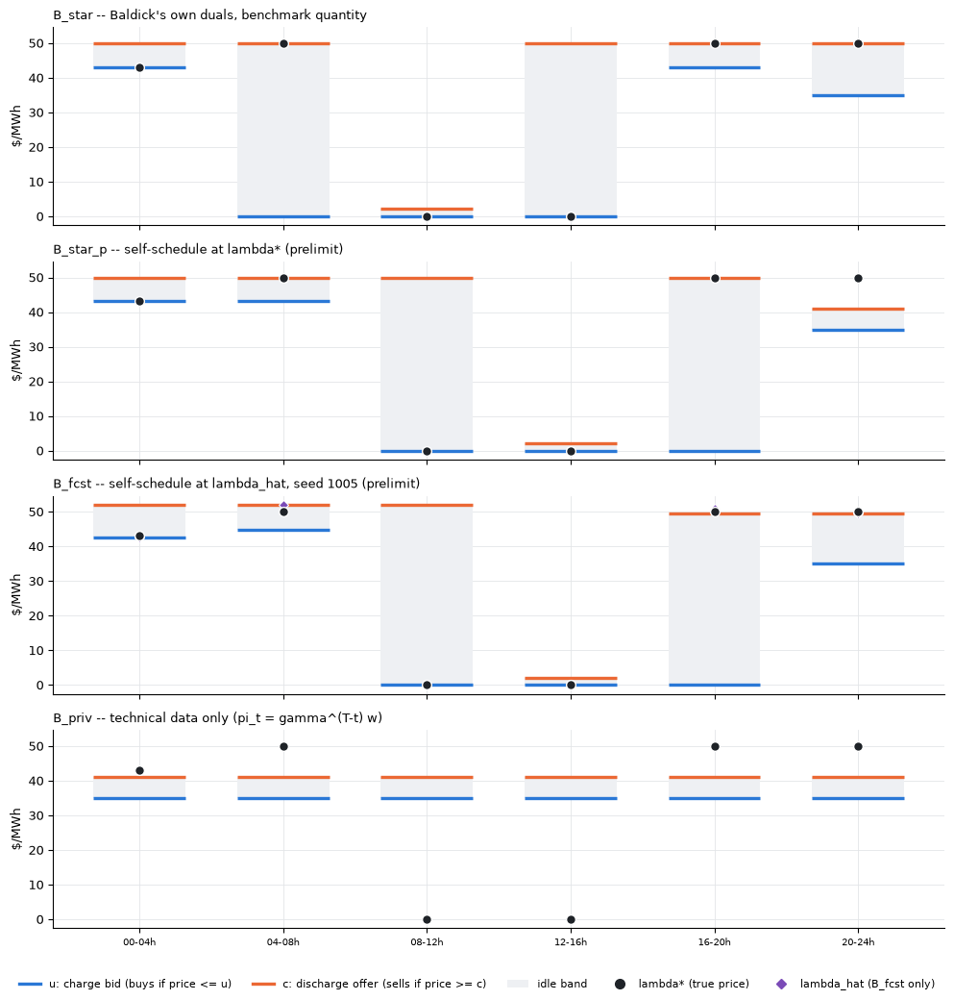

B_star        B_star_p        B_fcst        B_priv      
         lambda*      u      c        u      c      u      c      u     c
interval                                                                 
00-04h      43.1   43.1  50.00     43.1  50.00  42.58  51.96   35.0  41.0
04-08h      50.0    0.0  50.00     43.1  50.00  44.87  51.96   35.0  41.0
08-12h       0.0    0.0   2.11      0.0  50.00   0.00  51.96   35.0  41.0
12-16h       0.0    0.0  50.00      0.0   2.11   0.00   2.11   35.0  41.0
16-20h      50.0   43.1  50.00      0.0  50.00   0.00  49.48   35.0  41.0
20-24h      50.0   35.0  50.00     35.0  41.00  35.00  49.48   35.0  41.0

In [14]:
bid_star = bids.bid_star(S, bench.pi_star[0], bench.nuU_star[0], bench.nuL_star[0], bench.p_star[0], bench.g_star[0])
bid_star_p = bids.bid_star_p(S, lam_star, T, dT, RULE, KAPPA)
bid_fc = bids.bid_fcst(S, lam_hat, T, dT, RULE, KAPPA)
bid_priv = bids.bid_priv(S, T)
families = [("B_star -- Baldick's own duals, benchmark quantity", bid_star),
            (f"B_star_p -- self-schedule at lambda* ({RULE})", bid_star_p),
            (f"B_fcst -- self-schedule at lambda_hat, seed {SEED} ({RULE})", bid_fc),
            ("B_priv -- technical data only (pi_t = gamma^(T-t) w)", bid_priv)]

fig, axes = plt.subplots(len(families), 1, figsize=(10, 2.6 * len(families)), sharex=True, sharey=True)
for ax, (title, b) in zip(axes, families):
    for k in range(T):
        x0 = k + 1 - 0.32
        ax.add_patch(plt.Rectangle((x0, b.u[k]), 0.64, b.c[k] - b.u[k], fc="#eef0f3", ec="none", zorder=1))
        ax.hlines(b.u[k], x0, x0 + 0.64, color=COL["charge"], lw=2.4, zorder=2)
        ax.hlines(b.c[k], x0, x0 + 0.64, color=COL["discharge"], lw=2.4, zorder=2)
    ax.plot(t, lam_star, "o", color=COL["price"], ms=7, mec="white", mew=1, zorder=4)
    if b is bid_fc:
        ax.plot(t, lam_hat, "D", color=COL["forecast"], ms=5, mec="white", mew=0.8, zorder=3)
    ax.set_title(title, loc="left", fontsize=9.5)
    ax.set_ylabel("$/MWh")
    set_interval_axis(ax, T, dT)
handles = [plt.Line2D([], [], color=COL["charge"], lw=2.4), plt.Line2D([], [], color=COL["discharge"], lw=2.4),
           plt.Rectangle((0, 0), 1, 1, fc="#eef0f3"),
           plt.Line2D([], [], ls="none", marker="o", color=COL["price"], ms=7),
           plt.Line2D([], [], ls="none", marker="D", color=COL["forecast"], ms=5)]
fig.legend(handles, ["u: charge bid (buys if price <= u)", "c: discharge offer (sells if price >= c)",
                     "idle band", "lambda* (true price)", "lambda_hat (B_fcst only)"],
           loc="lower center", ncol=5, fontsize=8)
fig.tight_layout(rect=(0, 0.035, 1, 1)); plt.show()

bid_table = pd.DataFrame({(name.split(" ")[0], side): getattr(b, side) for name, b in families for side in ("u", "c")},
                         index=hours)
bid_table.insert(0, ("", "lambda*"), lam_star)
display(bid_table.round(2))

`B_star`'s band touches `lambda*` wherever the battery is marginal (Theorem 1): that is what makes the
current design reproduce Baldick's dispatch. `B_star_p` and `B_fcst` choose other points of the same
multiplier set, so their bands are placed differently even with no forecast error. `B_priv` knows nothing
about *when* prices are high: its band is flat (here `gamma = 1`), so it offers the same deal every interval.

## 5. Day-ahead clearing and the quantity rule

Each bid price becomes **two blocks** split at the planned quantity, `delta=\$0.01/MWh`
apart (`bids.quantity_blocks`), then `market.clear_cd` clears every hour as an
independent LP (hour-by-hour, since this system's generator ramp limits are
non-binding) -- `experiments.md` section 4.4.

In [15]:
blocks_star = bids.quantity_blocks(bid_star, S, delta=0.01, full_capacity=False)
da_star = market.clear_cd(case, [blocks_star], voll=1000.0)

check = pd.DataFrame({
    "p* (benchmark)": bench.p_star[0].round(3), "p_da (B_star)": da_star.p_da[0].round(3),
    "g* (benchmark)": bench.g_star[0].round(3), "g_da (B_star)": da_star.g_da[0].round(3),
    "lambda*": bench.lam_star[0].round(4), "lambda_cd (B_star)": da_star.lam_cd.round(4),
}, index=pd.RangeIndex(1, T + 1, name="hour"))
check


,p* (benchmark),p_da (B_star),g* (benchmark),g_da (B_star),lambda*,lambda_cd (B_star)
hour,,,,,,
1,100.000,100.000,0.0,0.0,43.1,43.09
2,0.000,0.000,90.0,90.0,50.0,50.00
3,200.000,200.000,0.0,0.0,0.0,-0.00
4,22.222,22.222,0.0,0.0,0.0,-0.00
5,0.000,0.000,175.0,175.0,50.0,49.99
6,0.000,0.000,25.0,25.0,50.0,50.00


In [16]:
max_p_diff = np.max(np.abs(da_star.p_da[0] - bench.p_star[0]))
max_g_diff = np.max(np.abs(da_star.g_da[0] - bench.g_star[0]))
max_lam_diff = np.max(np.abs(da_star.lam_cd - bench.lam_star[0]))
print(f"max |dispatch diff| : charge {max_p_diff:.2e} MW, discharge {max_g_diff:.2e} MW  -> EXACT")
print(f"max |price diff|    : {max_lam_diff:.4f} $/MWh  (<= delta=0.01, the quantity rule's own spread -- expected, not an error)")
print(f"load shed           : {da_star.shed.sum():.2e} MWh")


max |dispatch diff| : charge 0.00e+00 MW, discharge 0.00e+00 MW  -> EXACT
max |price diff|    : 0.0100 $/MWh  (<= delta=0.01, the quantity rule's own spread -- expected, not an error)
load shed           : 0.00e+00 MWh


Dispatch matches the benchmark to floating-point precision; the \$0.01 price gap is
exactly the quantity rule's own block spread, not a modelling error -- and since welfare
depends on *quantities* (at the ESS's true `eps`/`zeta`/`w`), not on the clearing price,
it has no effect on `dSW`.

## 6. Real-time repair and redispatch (`experiments.md` section 4.5)

Day-ahead dispatch can be SOC-infeasible for an ESS whose bid didn't anticipate its own
future state (this never happens for `B_star`, since it bids the feasible benchmark
schedule itself -- shown here for `B_priv`, which bids full capacity blindly).

In [17]:
blocks_priv = bids.quantity_blocks(bid_priv, S, delta=0.01, full_capacity=True)
da_priv = market.clear_cd(case, [blocks_priv], voll=1000.0)
repair_priv = realtime.feasible_schedule(S, da_priv.p_da[0], da_priv.g_da[0], T, dT)

rt_check = pd.DataFrame({
    "p_da (B_priv)": da_priv.p_da[0].round(2), "p_rt (repaired)": repair_priv.p.round(2),
    "g_da (B_priv)": da_priv.g_da[0].round(2), "g_rt (repaired)": repair_priv.g.round(2),
    "s_rt (MWh)": repair_priv.s.round(2),
}, index=pd.RangeIndex(1, T + 1, name="hour"))
rt_check
print(f"undeliverable energy: {repair_priv.undeliverable_mwh:.2f} MWh "
      f"(dT * sum|p-p_da|+|g-g_da| -- B_priv's blind full-capacity bid needs heavy correction)")
rt_check


undeliverable energy: 1051.11 MWh (dT * sum|p-p_da|+|g-g_da| -- B_priv's blind full-capacity bid needs heavy correction)


,p_da (B_priv),p_rt (repaired),g_da (B_priv),g_rt (repaired),s_rt (MWh)
hour,,,,,
1,100.0,100.00,0.0,0.0,360.0
2,0.0,0.00,100.0,90.0,-0.0
3,200.0,22.22,0.0,-0.0,80.0
4,200.0,200.00,0.0,0.0,800.0
5,0.0,0.00,175.0,100.0,400.0
6,0.0,0.00,100.0,100.0,-0.0


## 7. One draw, end to end: bid -> day-ahead market -> real time -> welfare

The same seed and settings as Section 3, pushed through exactly the pipeline of `runner.run_draw`
(family `B_fcst`): `bids.bid_fcst` -> `bids.quantity_blocks` -> `runner.evaluate_blocks`
(= `market.clear_cd`, `realtime.feasible_schedule`, `realtime.redispatch_hour`, `welfare.realised_welfare`).

### 7.1 The battery builds its bid from `lambda_hat`

It solves its own self-schedule against `lambda_hat` (M3) -- the planned quantities -- and picks multipliers
from the Prop. 5 polyhedron with the chosen rule (M4) -- the prices
$u_t = \alpha(\pi_t - \bar\nu_t) - \varepsilon$, $c_t = \zeta + \beta(\pi_t + \underline\nu_t)$.

,lambda* ($/MWh),lambda_hat ($/MWh),planned charge p0 (MW),planned discharge g0 (MW),planned SOC (MWh),charge bid u ($/MWh),discharge offer c ($/MWh),benchmark p* (MW),benchmark g* (MW)
interval,,,,,,,,,
00-04h,43.1,42.578,222.222,0.0,800.0,42.578,51.965,100.000,0.0
04-08h,50.0,51.965,0.000,200.0,0.0,44.868,51.965,0.000,90.0
08-12h,0.0,0.000,0.000,0.0,0.0,0.000,51.965,200.000,0.0
12-16h,0.0,0.000,222.222,0.0,800.0,0.000,2.111,22.222,0.0
16-20h,50.0,50.828,0.000,200.0,0.0,0.000,49.484,0.000,175.0
20-24h,50.0,49.484,0.000,0.0,0.0,35.000,49.484,0.000,25.0


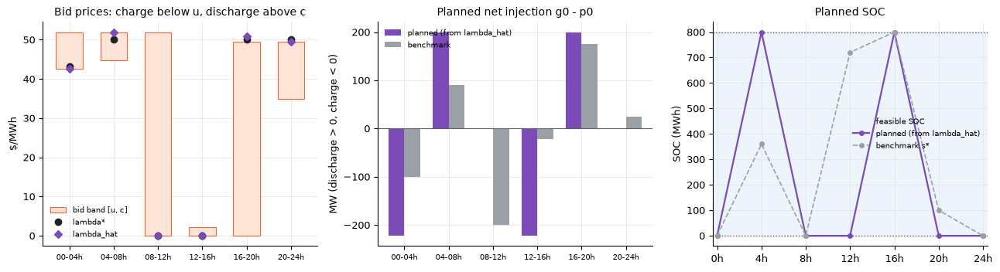

In [18]:
bid_f = bids.bid_fcst(S, lam_hat, T, dT, RULE, KAPPA)
s_plan = soc_path(S, bid_f.p0, bid_f.g0, dT)

bid_df = pd.DataFrame({
    "lambda* ($/MWh)": lam_star, "lambda_hat ($/MWh)": lam_hat,
    "planned charge p0 (MW)": bid_f.p0, "planned discharge g0 (MW)": bid_f.g0, "planned SOC (MWh)": s_plan,
    "charge bid u ($/MWh)": bid_f.u, "discharge offer c ($/MWh)": bid_f.c,
    "benchmark p* (MW)": bench.p_star[0], "benchmark g* (MW)": bench.g_star[0],
}, index=hours).round(3)
display(bid_df)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]
for k in range(T):
    ax.add_patch(plt.Rectangle((k + 1 - 0.3, bid_f.u[k]), 0.6, bid_f.c[k] - bid_f.u[k],
                               fc="#fde4d6", ec=COL["discharge"], lw=0.8, label="bid band [u, c]" if k == 0 else None))
ax.plot(t, lam_star, "o", color=COL["price"], ms=6, label="lambda*")
ax.plot(t, lam_hat, "D", color=COL["forecast"], ms=5, label="lambda_hat")
set_interval_axis(ax, T, dT); ax.set_ylabel("$/MWh"); ax.set_title("Bid prices: charge below u, discharge above c")
ax.legend(fontsize=7.5); ax.autoscale_view()

ax = axes[1]
w = 0.36
ax.bar(t - w / 2, bid_f.g0 - bid_f.p0, w, color=COL["forecast"], label="planned (from lambda_hat)")
ax.bar(t + w / 2, bench.g_star[0] - bench.p_star[0], w, color=COL["bench"], label="benchmark")
ax.axhline(0, color=COL["bound"], lw=0.8)
set_interval_axis(ax, T, dT); ax.set_ylabel("MW (discharge > 0, charge < 0)")
ax.set_title("Planned net injection g0 - p0"); ax.legend(fontsize=7.5)

ax = axes[2]
soc_axis(ax, S, T, dT)
plot_soc(ax, S, s_plan, color=COL["forecast"], lw=1.6, label="planned (from lambda_hat)")
plot_soc(ax, S, bench.s_star[0], color=COL["bench"], lw=1.2, ls="--", label="benchmark s*")
ax.set_title("Planned SOC"); ax.legend(fontsize=7.5)
fig.tight_layout(); plt.show()

### 7.2 The submitted curve: two blocks per side

`bids.quantity_blocks`: the planned quantity is offered `delta` = 0.01 \$/MWh more attractively than the rest
of the capacity, so the market prefers the planned schedule at a price equal to the bid.

In [19]:
delta = BidRule().delta
blocks_f = bids.quantity_blocks(bid_f, S, delta, full_capacity=False)
rows = []
for k in range(T):
    for side in ("charge", "discharge"):
        for j, (price, mw) in enumerate(blocks_f[side][k], start=1):
            rows.append({"interval": hours[k], "side": side, "block": j, "price ($/MWh)": price, "MW": mw})
blocks_df = pd.DataFrame(rows).pivot_table(index="interval", columns=["side", "block"],
                                           values=["price ($/MWh)", "MW"], sort=False)
display(blocks_df.round(2))

price ($/MWh)                              MW                           
side            charge        discharge         charge          discharge        
block                1      2         1      2       1        2         1       2
interval                                                                         
00-04h           42.59  42.57     51.95  51.97  222.22   777.78       0.0  1000.0
04-08h           44.88  44.86     51.95  51.97    0.00  1000.00     200.0   800.0
08-12h            0.01  -0.01     51.95  51.97    0.00  1000.00       0.0  1000.0
12-16h            0.01  -0.01      2.10   2.12  222.22   777.78       0.0  1000.0
16-20h            0.01  -0.01     49.47  49.49    0.00  1000.00     200.0   800.0
20-24h           35.01  34.99     49.47  49.49    0.00  1000.00       0.0  1000.0

### 7.3 Day-ahead clearing: every interval is a separate merit-order auction

`market.clear_hour` clears each interval alone: generators at their true cost, the battery's offer blocks as
extra supply, its bid blocks as extra demand, shedding at VOLL. The price `lambda_cd` is where supply meets
demand. **There is no SOC in this clearing** -- nothing stops it from accepting a schedule the battery cannot
physically follow.

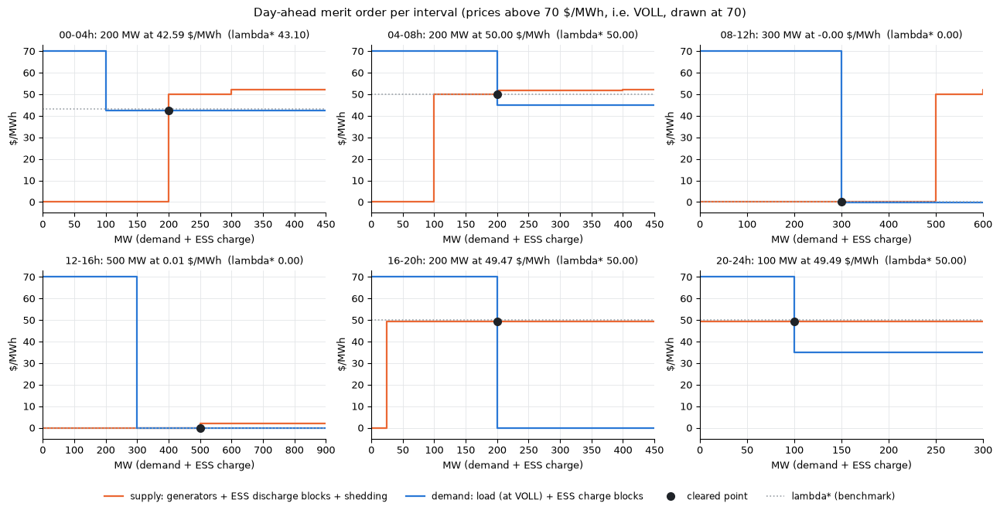

In [20]:
outcome = runner.evaluate_blocks(case, [blocks_f], RealTime(psi=PSI))
da = outcome.da
voll = RealTime().voll


def merit_order(ax, k):
    """Supply and demand curves of interval k as the clearing LP sees them."""
    D = case["D"][0][k]
    supply = [(c, cap[k]) for c, cap in zip([cost for G in case["gens"] for cost, _ in G["blocks"]], caps)]
    supply += [(pr, mw) for pr, mw in blocks_f["discharge"][k]] + [(voll, D)]
    supply = sorted([(pr, mw) for pr, mw in supply if mw > 1e-9])
    demand = [(voll, D)] + sorted([(pr, mw) for pr, mw in blocks_f["charge"][k] if mw > 1e-9], reverse=True)
    ytop = 70
    for curve, col, lab in [(supply, COL["discharge"], "supply"), (demand, COL["charge"], "demand")]:
        x = np.r_[0, np.cumsum([mw for _, mw in curve])]
        y = [min(pr, ytop) for pr, _ in curve]
        ax.step(x, np.r_[y, y[-1]], where="post", color=col, lw=1.6, label=lab)
    cleared = D + da.p_da[0][k]
    ax.plot(cleared, min(da.lam_cd[k], ytop), "o", color=COL["price"], ms=7, zorder=5, label="cleared point")
    ax.axhline(lam_star[k], color=COL["bench"], ls=":", lw=1.2, label="lambda* (benchmark)")
    ax.set_xlim(0, cleared * 1.5 + 150); ax.set_ylim(-5, ytop + 3)
    ax.set_title(f"{hours[k]}: {cleared:.0f} MW at {da.lam_cd[k]:.2f} $/MWh  (lambda* {lam_star[k]:.2f})", fontsize=9)
    ax.set_xlabel("MW (demand + ESS charge)"); ax.set_ylabel("$/MWh")


fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
for k, ax in enumerate(axes.flat):
    merit_order(ax, k)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, ["supply: generators + ESS discharge blocks + shedding",
                     "demand: load (at VOLL) + ESS charge blocks", "cleared point", "lambda* (benchmark)"],
           loc="lower center", ncol=4, fontsize=8.5)
fig.suptitle("Day-ahead merit order per interval (prices above 70 $/MWh, i.e. VOLL, drawn at 70)")
fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

,demand (MW),renewable q_da (MW),thermal (50 $/MWh) q_da (MW),ESS charge p_da (MW),ESS discharge g_da (MW),shed (MW),lambda_cd ($/MWh),lambda* ($/MWh),SOC if delivered (MWh),SOC feasible?
interval,,,,,,,,,,
00-04h,100.0,200.0,0.0,100.0,0.0,0.0,42.59,43.1,360.0,yes
04-08h,200.0,100.0,100.0,0.0,0.0,0.0,50.00,50.0,360.0,yes
08-12h,300.0,300.0,0.0,0.0,0.0,0.0,-0.00,0.0,360.0,yes
12-16h,300.0,500.0,0.0,200.0,0.0,0.0,0.01,0.0,1080.0,NO
16-20h,200.0,25.0,0.0,0.0,175.0,0.0,49.47,50.0,380.0,yes
20-24h,100.0,0.0,0.0,0.0,100.0,0.0,49.49,50.0,-20.0,NO


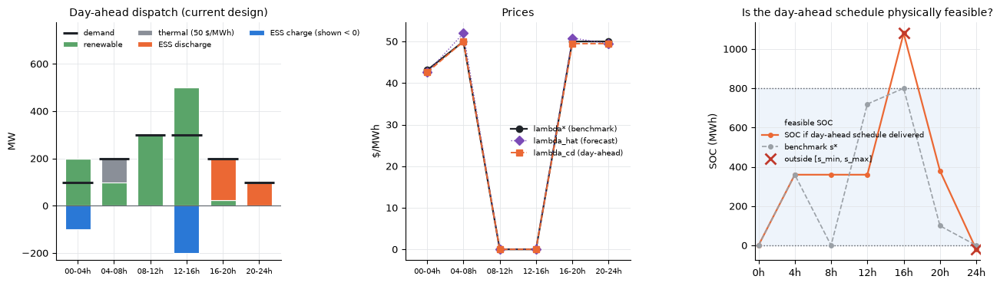

In [21]:
s_da = soc_path(S, da.p_da[0], da.g_da[0], dT)   # where the day-ahead schedule WOULD take the battery
feasible = (s_da >= S["smin"] - 1e-6) & (s_da <= S["smax"] + 1e-6)

da_df = pd.DataFrame({"demand (MW)": case["D"][0]}, index=hours)
for name, q in zip(names, da.q_da):
    da_df[f"{name} q_da (MW)"] = q
da_df["ESS charge p_da (MW)"] = da.p_da[0]
da_df["ESS discharge g_da (MW)"] = da.g_da[0]
da_df["shed (MW)"] = da.shed
da_df["lambda_cd ($/MWh)"] = da.lam_cd
da_df["lambda* ($/MWh)"] = lam_star
da_df["SOC if delivered (MWh)"] = s_da
da_df["SOC feasible?"] = np.where(feasible, "yes", "NO")
display(da_df.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
energy_balance(axes[0], case, da.q_da, da.p_da[0], da.g_da[0], da.shed, "Day-ahead dispatch (current design)")
ax = axes[1]
ax.plot(t, lam_star, "o-", color=COL["price"], lw=1.6, label="lambda* (benchmark)")
ax.plot(t, lam_hat, "D:", color=COL["forecast"], lw=1, label="lambda_hat (forecast)")
ax.plot(t, np.minimum(da.lam_cd, 100), "s--", color=COL["discharge"], lw=1.4, label="lambda_cd (day-ahead)")
set_interval_axis(ax, T, dT); ax.set_ylabel("$/MWh"); ax.set_title("Prices"); ax.legend(fontsize=7.5)
ax = axes[2]
soc_axis(ax, S, T, dT)
plot_soc(ax, S, s_da, color=COL["discharge"], lw=1.6, label="SOC if day-ahead schedule delivered")
plot_soc(ax, S, bench.s_star[0], color=COL["bench"], lw=1.2, ls="--", label="benchmark s*")
bad = np.where(~feasible)[0]
ax.plot(bad + 1.5, s_da[bad], "x", color=COL["bad"], ms=10, mew=2, label="outside [s_min, s_max]")
ax.set_title("Is the day-ahead schedule physically feasible?"); ax.legend(fontsize=7.5)
fig.tight_layout(); plt.show()

**Does the battery buy the free energy?** In the free intervals the market price is 0, so a charge block is
accepted only if its bid is at least 0. The bid there follows the forecast (where the battery plans to charge,
$u_t = \hat\lambda_t$). With the price floor the forecast is never negative there. **Without** it, a draw whose
forecast was negative in both free intervals bought nothing, arrived at 16-20h (the shortfall interval) empty,
and real time shed 75 MW at VOLL -- about 1 draw in 5, at every `sigma`. The cell compares the same seed with
and without the floor.

In [22]:
free_df = pd.DataFrame({
    "lambda* ($/MWh)": lam_star[free], "lambda_hat ($/MWh)": lam_hat[free],
    "charge bid u ($/MWh)": bid_f.u[free], "block 2 price u - delta": bid_f.u[free] - delta,
    "bought day-ahead p_da (MW)": da.p_da[0][free],
}, index=hours[free]).round(3)
display(free_df)


def free_hours_outcome(err):
    """The same seed through the whole pipeline under error model `err`."""
    lh = forecasts.forecast_prices(lam_star, err, 1, T, np.random.default_rng(SEED))[0]
    bf = bids.bid_fcst(S, lh, T, dT, RULE, KAPPA)
    out = runner.evaluate_blocks(case, [bids.quantity_blocks(bf, S, delta, full_capacity=False)], RealTime(psi=PSI))
    return {"lambda_hat in free intervals": np.round(lh[free], 2), "charge bids u there": np.round(bf.u[free], 2),
            "MWh bought there": dT * out.da.p_da[0][free].sum(), "shed in real time (MWh)": dT * out.shed_rt.sum(),
            "dSW (% of V)": round(metrics.dsw_pct(metrics.dsw(bench.SW_star, out.welfare.SW_real), bench.V), 2)}


floor_cmp = pd.DataFrame({
    f"price floor {PRICE_FLOOR}": free_hours_outcome(error),
    "no price floor": free_hours_outcome(ErrorModel(sigma_abs=SIGMA, rho=RHO, bias_pct=BIAS_PCT, price_floor=None)),
}).T
display(floor_cmp)
print(f"benchmark buys {dT * bench.p_star[0][free].sum():.0f} MWh in the free intervals")

,lambda* ($/MWh),lambda_hat ($/MWh),charge bid u ($/MWh),block 2 price u - delta,bought day-ahead p_da (MW)
interval,,,,,
08-12h,0.0,0.0,0.0,-0.01,0.0
12-16h,0.0,0.0,0.0,-0.01,200.0


,lambda_hat in free intervals,charge bids u there,MWh bought there,shed in real time (MWh),dSW (% of V)
price floor 0.0,"[0.0, 0.0]","[0.0, 0.0]",800.0,0.0,2.83
no price floor,"[-2.01, -0.64]","[-0.64, -0.64]",0.0,300.0,96.23


benchmark buys 889 MWh in the free intervals


### 7.4 Real time: the battery does what it physically can, generators fill the gap

1. `realtime.feasible_schedule` (M6): the battery delivers the SOC-feasible schedule closest (L1) to what it
   sold -- with its **true** parameters.
2. `realtime.redispatch_hour` (M7): generators move away from `q_da` to cover the difference, paying their
   own cost plus the premium `psi` per MWh moved up **or** down; any shortfall is shed at VOLL.

,p_da (MW),p_rt (MW),g_da (MW),g_rt (MW),SOC if delivered (MWh),SOC real time (MWh),renewable: q_da -> q_rt (MW),thermal (50 $/MWh): q_da -> q_rt (MW),redispatched (MW),shed in real time (MW)
interval,,,,,,,,,,
00-04h,100.0,100.0,0.0,0.0,360.0,360.0,200.0 -> 200.0,0.0 -> 0.0,0.0,0.0
04-08h,0.0,0.0,0.0,70.0,360.0,80.0,100.0 -> 100.0,100.0 -> 30.0,70.0,0.0
08-12h,0.0,0.0,0.0,0.0,360.0,80.0,300.0 -> 300.0,0.0 -> 0.0,0.0,0.0
12-16h,200.0,200.0,0.0,0.0,1080.0,800.0,500.0 -> 500.0,0.0 -> 0.0,0.0,0.0
16-20h,0.0,0.0,175.0,100.0,380.0,400.0,25.0 -> 25.0,0.0 -> 75.0,75.0,0.0
20-24h,0.0,0.0,100.0,100.0,-20.0,-0.0,0.0 -> 0.0,0.0 -> 0.0,0.0,0.0


undeliverable battery energy = 580.0 MWh   (dT * sum |p_rt - p_da| + |g_rt - g_da|)
generator energy redispatched = 580.0 MWh at premium psi = 10.0 $/MWh


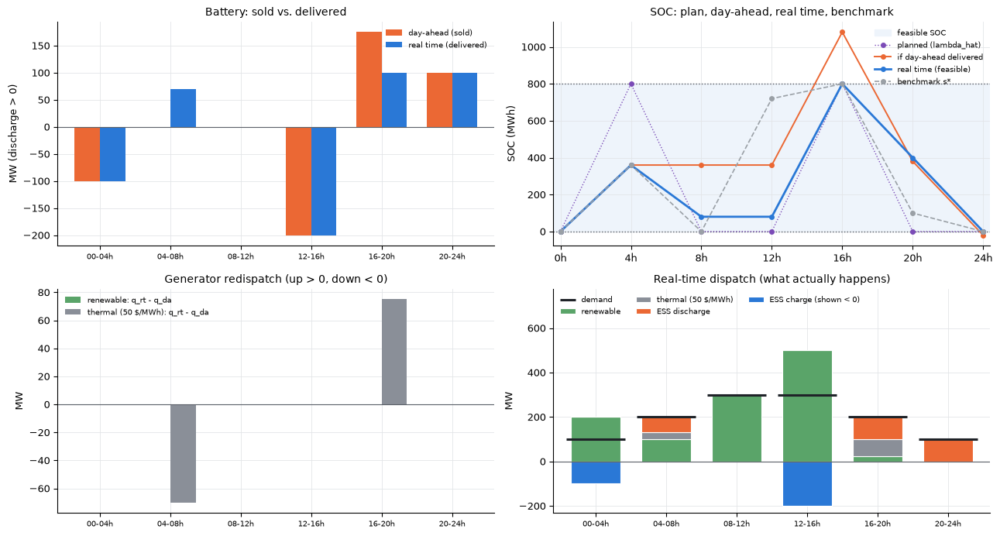

In [23]:
rt_df = pd.DataFrame({
    "p_da (MW)": da.p_da[0], "p_rt (MW)": outcome.p_rt[0],
    "g_da (MW)": da.g_da[0], "g_rt (MW)": outcome.g_rt[0],
    "SOC if delivered (MWh)": s_da, "SOC real time (MWh)": outcome.s_rt[0],
}, index=hours)
for name, qd, qr in zip(names, da.q_da, outcome.q_rt):
    rt_df[f"{name}: q_da -> q_rt (MW)"] = [f"{a:.1f} -> {b:.1f}" for a, b in zip(qd, qr)]
rt_df["redispatched (MW)"] = outcome.redispatched_mw
rt_df["shed in real time (MW)"] = outcome.shed_rt
display(rt_df.round(2))
print(f"undeliverable battery energy = {outcome.undeliverable_mwh:.1f} MWh   "
      f"(dT * sum |p_rt - p_da| + |g_rt - g_da|)")
print(f"generator energy redispatched = {dT * outcome.redispatched_mw.sum():.1f} MWh at premium psi = {PSI} $/MWh")

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
ax = axes[0, 0]
w = 0.36
ax.bar(t - w / 2, da.g_da[0] - da.p_da[0], w, color=COL["discharge"], label="day-ahead (sold)")
ax.bar(t + w / 2, outcome.g_rt[0] - outcome.p_rt[0], w, color=COL["charge"], label="real time (delivered)")
ax.axhline(0, color=COL["bound"], lw=0.8)
set_interval_axis(ax, T, dT); ax.set_ylabel("MW (discharge > 0)"); ax.set_title("Battery: sold vs. delivered")
ax.legend(fontsize=7.5)

ax = axes[0, 1]
soc_axis(ax, S, T, dT)
plot_soc(ax, S, s_plan, color=COL["forecast"], lw=1, ls=":", label="planned (lambda_hat)")
plot_soc(ax, S, s_da, color=COL["discharge"], lw=1.4, label="if day-ahead delivered")
plot_soc(ax, S, outcome.s_rt[0], color=COL["charge"], lw=2, label="real time (feasible)")
plot_soc(ax, S, bench.s_star[0], color=COL["bench"], lw=1.2, ls="--", label="benchmark s*")
ax.set_title("SOC: plan, day-ahead, real time, benchmark"); ax.legend(fontsize=7.5)

ax = axes[1, 0]
dq = outcome.q_rt - da.q_da
for j, (name, row) in enumerate(zip(names, dq)):
    ax.bar(t + (j - 0.5) * w, row, w, label=f"{name}: q_rt - q_da",
           color=COL["renewable" if name == "renewable" else "thermal"])
hit = outcome.shed_rt > 1e-9
if hit.any():
    ax.bar(t[hit] + 1.5 * w, outcome.shed_rt[hit], w, color=COL["shed"], label="load shed in real time")
ax.axhline(0, color=COL["bound"], lw=0.8)
set_interval_axis(ax, T, dT); ax.set_ylabel("MW"); ax.set_title("Generator redispatch (up > 0, down < 0)")
ax.legend(fontsize=7.5)

energy_balance(axes[1, 1], case, outcome.q_rt, outcome.p_rt[0], outcome.g_rt[0], outcome.shed_rt,
               "Real-time dispatch (what actually happens)")
fig.tight_layout(); plt.show()

### 7.5 Welfare: the same yardstick as the benchmark

`welfare.realised_welfare` with the true battery parameters, against `SW_star` from Section 2.

In [24]:
w_draw = outcome.welfare
parts = ["generation_cost", "redispatch_cost", "shed_cost", "degradation_cost", "terminal_value"]
welfare_df = pd.DataFrame({
    "benchmark ($)": [getattr(w_bench, p) for p in parts] + [w_bench.SW_real],
    f"seed {SEED} ($)": [getattr(w_draw, p) for p in parts] + [w_draw.SW_real],
}, index=[p.replace("_", " ") for p in parts] + ["SW = -(costs - terminal value)"])
welfare_df["difference ($)"] = welfare_df.iloc[:, 1] - welfare_df.iloc[:, 0]
display(welfare_df.round(2))

dsw = metrics.dsw(bench.SW_star, w_draw.SW_real)
print(f"dSW = SW_star - SW_real = {dsw:,.2f} $  =  {metrics.dsw_pct(dsw, bench.V):.2f} % of the storage value V")

,benchmark ($),seed 1005 ($),difference ($)
generation cost,17000.00,21000.0,4000.00
redispatch cost,0.00,5800.0,5800.00
shed cost,0.00,0.0,0.00
degradation cost,2448.89,2280.0,-168.89
terminal value,0.00,0.0,0.00
SW = -(costs - terminal value),-19448.89,-29080.0,-9631.11


dSW = SW_star - SW_real = 9,631.11 $  =  2.83 % of the storage value V


### 7.6 Which seed to look at?

The same pipeline for a range of seeds with the settings above, **with and without the price floor** -- pick
one and set `SEED` in Section 3. With the floor no draw sheds load; without it, every draw that sheds load is one
that bought nothing in the free intervals (checked by the asserts).

In [25]:
scan = []
error_nofloor = ErrorModel(sigma_abs=SIGMA, rho=RHO, bias_pct=BIAS_PCT, price_floor=None)
for seed in range(1000, 1020):
    row = {"seed": seed}
    for tag, err in (("floor", error), ("no floor", error_nofloor)):
        lh = forecasts.forecast_prices(lam_star, err, 1, T, np.random.default_rng(seed))[0]
        bf = bids.bid_fcst(S, lh, T, dT, RULE, KAPPA)
        out = runner.evaluate_blocks(case, [bids.quantity_blocks(bf, S, delta, full_capacity=False)], RealTime(psi=PSI))
        d = metrics.dsw(bench.SW_star, out.welfare.SW_real)
        row[(tag, "min lambda_hat free")] = lh[free].min()
        row[(tag, "MWh bought free")] = dT * out.da.p_da[0][free].sum()
        row[(tag, "shed (MWh)")] = dT * out.shed_rt.sum()
        row[(tag, "dSW (% of V)")] = metrics.dsw_pct(d, bench.V)
    scan.append(row)
scan_df = pd.DataFrame(scan).set_index("seed")
scan_df.columns = pd.MultiIndex.from_tuples(scan_df.columns)
display(scan_df.round(2))
assert (scan_df[("floor", "shed (MWh)")] == 0).all()
shed_nf = scan_df[("no floor", "shed (MWh)")] > 0
assert (scan_df.loc[shed_nf, ("no floor", "MWh bought free")] == 0).all()

floor                                                    no floor                                        
     min lambda_hat free MWh bought free shed (MWh) dSW (% of V) min lambda_hat free MWh bought free shed (MWh) dSW (% of V)
seed                                                                                                                        
1000                0.00          1600.0        0.0         9.31               -0.88          1600.0        0.0         9.31
1001                0.00          1600.0        0.0         8.70               -0.31          1600.0        0.0         8.70
1002                0.00          1600.0        0.0         9.31               -0.61          1600.0        0.0         9.31
1003                0.30          1600.0        0.0         9.31                0.30          1600.0        0.0         9.31
1004                0.00          1600.0        0.0         9.31               -1.06          1600.0        0.0         9.31
1005                0.00           800.0        0.0         2.83               -2.01             0.0      300.0        96.23
1006                0.00          1600.0        0.0         3.09               -0.37          1600.0        0.0         3.09
1007                0.00           800.0        0.0         2.83               -1.97             0.0      300.0        96.23
1008                0.00          1600.0        0.0         3.09               -1.53          1600.0        0.0         3.09
1009                0.00           800.0        0.0         7.38               -0.39             0.0        0.0        11.41
1010                0.00          1600.0        0.0         9.31               -1.12          1600.0        0.0         9.31
1011                0.24          1600.0        0.0         9.31                0.24          1600.0        0.0         9.31
1012                0.00          1600.0        0.0         9.31               -0.99          1600.0        0.0         9.31
1013                0.00          1600.0        0.0         9.31               -0.88          1600.0        0.0         9.31
1014                0.00          1600.0        0.0         8.70               -1.07          1600.0        0.0         8.70
1015                0.00           800.0        0.0         2.83               -1.31             0.0      300.0        96.23
1016                0.00          1600.0        0.0         9.31               -0.80          1600.0        0.0         9.31
1017                0.00           800.0        0.0         2.83               -1.02             0.0      300.0        96.23
1018                0.31          1600.0        0.0         2.47                0.31          1600.0        0.0         2.47
1019                0.00           800.0        0.0         2.83               -0.10             0.0      300.0        96.23

### 7.7 Interactive explorer: choose the error, see day-ahead and real time

Every change re-runs the real pipeline for one draw (`forecasts.forecast_prices` -> `bids.bid_fcst` ->
`bids.quantity_blocks` -> `runner.evaluate_blocks`), about 0.03 s. The seed fixes the random error *shape*;
`sigma`, `rho`, bias and the price floor decide how that shape becomes `lambda_hat`. Same seed + same settings
= same draw as Sections 3 and 7. Needs a running kernel (in VS Code: the `DTU_SYS` Python).

**Why a new seed sometimes seems to change nothing.** The forecast always changes -- panel (a) shows it on its
own scale -- but the market outcome is piecewise constant: the battery's schedule only switches when the
forecast crosses a decision threshold (a vertex of the LPs). At `sigma` = 1 \$/MWh, 40 seeds give only 8
different day-ahead battery schedules; at `sigma` >= 5, about 15. The status line under the controls says
whether the last change moved the dispatch, and in which intervals.

**Animate.** Pick a parameter in *animate* and press play: it steps through that parameter's range (or through
seeds, +1 per step) and re-solves at every step. The axes keep their scale while you change a parameter, so
only the data moves. For a perfectly smooth, shareable version see 7.8.

In [26]:
from matplotlib import animation
from IPython.display import HTML

PARAM_LABEL = {"seed": "seed", "sigma": "sigma ($/MWh)", "rho": "rho", "bias_pct": "bias (% of mean price)",
               "psi": "psi ($/MWh)"}


def simulate_draw(seed, sigma, rho, bias_pct, floor_on, rule, psi):
    """One draw end to end; everything the panels need."""
    err = ErrorModel(sigma_abs=sigma, rho=rho, bias_pct=bias_pct, price_floor=0.0 if floor_on else None)
    lh = forecasts.forecast_prices(lam_star, err, 1, T, np.random.default_rng(seed))[0]
    bf = bids.bid_fcst(S, lh, T, dT, rule, KAPPA)
    out = runner.evaluate_blocks(case, [bids.quantity_blocks(bf, S, BidRule().delta, full_capacity=False)],
                                 RealTime(psi=psi))
    s_da = soc_path(S, out.da.p_da[0], out.da.g_da[0], dT)
    d = metrics.dsw(bench.SW_star, out.welfare.SW_real)
    return dict(params=dict(seed=seed, sigma=sigma, rho=rho, bias_pct=bias_pct, floor_on=floor_on, rule=rule, psi=psi),
                lam_hat=lh, bid=bf, out=out, s_plan=soc_path(S, bf.p0, bf.g0, dT), s_da=s_da,
                bad=np.where((s_da < S["smin"] - 1e-6) | (s_da > S["smax"] + 1e-6))[0],
                dsw=d, dsw_pct=metrics.dsw_pct(d, bench.V))


def _outward(lo, hi, step):
    return float(np.floor(lo / step) * step), float(np.ceil(hi / step) * step)


def panel_limits(results):
    """y-limits per panel that hold for every draw in `results`, rounded outward: redraws and animation frames
    keep the same scale, so only the data moves."""
    sig = max(r["params"]["sigma"] for r in results)
    b = max(abs(r["params"]["bias_pct"]) for r in results) / 100 * lam_bar
    e = max(max(np.abs(r["lam_hat"] - lam_star).max() for r in results), 3 * sig + b, 1.0)
    pr = np.concatenate([np.r_[r["lam_hat"], r["bid"].u, r["bid"].c, np.minimum(r["out"].da.lam_cd, 100)]
                         for r in results])
    soc = np.concatenate([np.r_[r["s_plan"], r["s_da"], r["out"].s_rt[0]] for r in results] + [bench.s_star[0]])
    top, pmax = case["D"][0].max(), 0.0
    for r in results:
        o = r["out"]
        for q, p, g, sh in ((o.da.q_da, o.da.p_da[0], o.da.g_da[0], o.da.shed), (o.q_rt, o.p_rt[0], o.g_rt[0], o.shed_rt)):
            top, pmax = max(top, (q.sum(0) + g + sh).max()), max(pmax, p.max())
    net = np.concatenate([np.r_[r["out"].da.g_da[0] - r["out"].da.p_da[0], r["out"].g_rt[0] - r["out"].p_rt[0]]
                          for r in results])
    rd = np.concatenate([np.r_[(r["out"].q_rt - r["out"].da.q_da).ravel(), r["out"].shed_rt] for r in results])
    return {"err": (-1.15 * e, 1.15 * e),
            "price": _outward(min(pr.min(), -5), max(pr.max(), 60), 10),
            "soc": _outward(min(soc.min(), -100), max(soc.max(), S["smax"] + 150), 200),
            "eb": _outward(min(-1.15 * pmax, -0.05 * top), 1.55 * top, 100),
            "net": _outward(1.1 * min(net.min(), -50), 1.45 * max(net.max(), 50), 50),
            "redisp": _outward(1.15 * min(rd.min(), -20), 1.5 * max(rd.max(), 20), 20)}


def cost_panel(ax, r):
    """Where the welfare loss comes from, cost by cost, against the benchmark (bars add up to dSW)."""
    w = r["out"].welfare
    parts = ["generation_cost", "redispatch_cost", "shed_cost", "degradation_cost"]
    diffs = [getattr(w, p) - getattr(w_bench, p) for p in parts] + [w_bench.terminal_value - w.terminal_value]
    labels = ["generation", "redispatch premium", "load shed (VOLL)", "degradation", "terminal value lost"]
    ax.barh(labels, np.array(diffs) / 1000, color=[COL["thermal"], COL["discharge"], COL["shed"], COL["bench"],
                                                   COL["charge"]])
    ax.axvline(0, color=COL["bound"], lw=0.8)
    ax.invert_yaxis(); ax.tick_params(axis="y", labelsize=7.5)
    ax.set_xlabel("k$ against the benchmark (> 0 = welfare lost)")
    ax.set_title(f"(h) Where the loss comes from: dSW = {r['dsw'] / 1000:,.1f} k$ = {r['dsw_pct']:.1f}% of V")


def draw_panels(axes, r, lim, panel_h):
    """The eight panels of one draw on a 2 x 4 grid of axes, with fixed limits `lim`; `panel_h(ax)` draws (h)."""
    o, bf, lh, p = r["out"], r["bid"], r["lam_hat"], r["params"]
    da = o.da
    ax = axes[0, 0]                                              # (a) the error itself
    err = lh - lam_star
    bias = p["bias_pct"] / 100 * lam_bar
    ax.axhspan(bias - p["sigma"], bias + p["sigma"], color=COL["forecast"], alpha=0.08, lw=0, label="bias +/- sigma")
    ax.bar(t, err, 0.6, color=COL["forecast"], label="lambda_hat - lambda*")
    ax.axhline(bias, color=COL["bench"], ls="--", lw=1.2, label=f"bias {bias:+.2f}")
    ax.axhline(0, color=COL["price"], lw=0.8)
    if p["floor_on"]:
        for k in np.where(np.isclose(lh, 0.0) & (lam_star + bias < 3 * p["sigma"]))[0]:
            ax.annotate("floor", (k + 1, err[k]), xytext=(0, 6), textcoords="offset points", ha="center",
                        fontsize=7, color=COL["bound"])
    set_interval_axis(ax, T, dT); ax.set_ylim(lim["err"]); ax.set_ylabel("$/MWh")
    ax.set_title(f"(a) Forecast error (seed {p['seed']})"); ax.legend(fontsize=6.5, loc="lower left", ncol=2)

    ax = axes[0, 1]                                              # (b) prices and bid bands
    for k in range(T):
        x0 = k + 1 - 0.32
        ax.add_patch(plt.Rectangle((x0, bf.u[k]), 0.64, bf.c[k] - bf.u[k], fc="#eef0f3", ec="none", zorder=1))
        ax.hlines(bf.u[k], x0, x0 + 0.64, color=COL["charge"], lw=2.2, zorder=2, label="charge bid u" if k == 0 else None)
        ax.hlines(bf.c[k], x0, x0 + 0.64, color=COL["discharge"], lw=2.2, zorder=2,
                  label="discharge offer c" if k == 0 else None)
    ax.plot(t, lam_star, "o", color=COL["price"], ms=7, mec="white", zorder=4, label="lambda*")
    ax.plot(t, lh, "D", color=COL["forecast"], ms=5, mec="white", zorder=4, label="lambda_hat")
    ax.plot(t, np.minimum(da.lam_cd, 100), "s", mfc="none", mec=COL["discharge"], ms=9, mew=1.5, zorder=3,
            label="lambda_cd (day-ahead)")
    set_interval_axis(ax, T, dT); ax.set_ylim(lim["price"]); ax.set_ylabel("$/MWh")
    ax.set_title("(b) Forecast, bid bands, prices"); ax.legend(fontsize=6.5, loc="center left")

    energy_balance(axes[0, 2], case, da.q_da, da.p_da[0], da.g_da[0], da.shed, "(c) Day-ahead dispatch")
    axes[0, 2].set_ylim(lim["eb"])

    ax = axes[0, 3]                                              # (d) SOC feasibility
    soc_axis(ax, S, T, dT)
    plot_soc(ax, S, bench.s_star[0], color=COL["bench"], lw=1.2, ls="--", label="benchmark s*")
    plot_soc(ax, S, r["s_plan"], color=COL["forecast"], lw=1, ls=":", label="planned")
    plot_soc(ax, S, r["s_da"], color=COL["discharge"], lw=1.5, label="if day-ahead delivered")
    plot_soc(ax, S, o.s_rt[0], color=COL["charge"], lw=2.2, label="real time")
    if len(r["bad"]):
        ax.plot(r["bad"] + 1.5, r["s_da"][r["bad"]], "x", color=COL["bad"], ms=11, mew=2.2, label="infeasible")
    ax.set_ylim(lim["soc"]); ax.set_title(f"(d) SOC: {len(r['bad'])} infeasible interval(s) day-ahead")
    ax.legend(fontsize=6.5, loc="lower left", ncol=2)

    ax = axes[1, 0]                                              # (e) sold vs delivered
    w = 0.36
    ax.bar(t - w / 2, da.g_da[0] - da.p_da[0], w, color=COL["discharge"], label="day-ahead (sold)")
    ax.bar(t + w / 2, o.g_rt[0] - o.p_rt[0], w, color=COL["charge"], label="real time (delivered)")
    ax.axhline(0, color=COL["bound"], lw=0.8)
    set_interval_axis(ax, T, dT); ax.set_ylim(lim["net"]); ax.set_ylabel("MW (discharge > 0)")
    ax.set_title(f"(e) Battery: {o.undeliverable_mwh:.0f} MWh undeliverable"); ax.legend(fontsize=6.5, loc="upper left")

    ax = axes[1, 1]                                              # (f) redispatch and shedding
    for j, (name, row) in enumerate(zip(block_names(case), o.q_rt - da.q_da)):
        ax.bar(t + (j - 0.5) * w, row, w, label=f"{name}: q_rt - q_da",
               color=COL["renewable" if name == "renewable" else "thermal"])
    hit = o.shed_rt > 1e-9
    if hit.any():
        ax.bar(t[hit] + 1.5 * w, o.shed_rt[hit], w, color=COL["shed"], label="load shed")
    ax.axhline(0, color=COL["bound"], lw=0.8)
    set_interval_axis(ax, T, dT); ax.set_ylim(lim["redisp"]); ax.set_ylabel("MW")
    ax.set_title(f"(f) Redispatch {dT * o.redispatched_mw.sum():.0f} MWh, shed {dT * o.shed_rt.sum():.0f} MWh")
    ax.legend(fontsize=6.5, loc="upper left")

    energy_balance(axes[1, 2], case, o.q_rt, o.p_rt[0], o.g_rt[0], o.shed_rt, "(g) Real-time dispatch")
    axes[1, 2].set_ylim(lim["eb"])
    panel_h(axes[1, 3])


def explorer_title(p):
    floor_txt = "floor 0" if p["floor_on"] else "no floor"
    return (f"seed {p['seed']}  |  sigma {p['sigma']:g} $/MWh, rho {p['rho']:g}, bias {p['bias_pct']:+g}%, "
            f"{floor_txt}, rule {p['rule']}, psi {p['psi']:g}")


def explorer_figure(seed, sigma, rho, bias_pct, floor_on, rule, psi):
    """Static version of the explorer (handy for saving thesis figures): returns (figure, draw)."""
    r = simulate_draw(seed, sigma, rho, bias_pct, floor_on, rule, psi)
    fig, axes = plt.subplots(2, 4, figsize=(20, 8.6))
    draw_panels(axes, r, panel_limits([r]), lambda ax: cost_panel(ax, r))
    fig.suptitle(explorer_title(r["params"]), fontsize=11)
    fig.tight_layout()
    return fig, r


def sweep_animation(param, values, base, fps=4, dpi=60, save_gif=None):
    """Pre-rendered animation of one parameter moving through `values` (all other settings from `base`).
    Axes are fixed over all frames; panel (h) tracks the welfare loss along the sweep. Returns (HTML, draws)."""
    results = [simulate_draw(**{**base, param: v}) for v in values]
    lim = panel_limits(results)
    xs = np.asarray(values, dtype=float)
    loss = np.array([r["dsw_pct"] for r in results])
    fig, axes = plt.subplots(2, 4, figsize=(20, 8.6), dpi=dpi)

    def tracker(ax, k):
        ax.plot(xs, loss, "-", color=COL["bench"], lw=1.2, label="whole sweep")
        ax.plot(xs[:k + 1], loss[:k + 1], "-", color=COL["price"], lw=2, label="so far")
        ax.plot(xs[k], loss[k], "o", color=COL["discharge"], ms=10, zorder=5)
        ax.set_xlabel(PARAM_LABEL.get(param, param)); ax.set_ylabel("dSW (% of V)")
        ax.set_ylim(*_outward(min(loss.min(), 0), max(loss.max(), 1) * 1.15, 1))
        ax.set_title(f"(h) Welfare loss along the sweep: {loss[k]:.1f}% of V"); ax.legend(fontsize=7)

    def frame(k):
        for ax in axes.flat:
            ax.clear()
        draw_panels(axes, results[k], lim, lambda ax: tracker(ax, k))
        fig.suptitle(explorer_title(results[k]["params"]), fontsize=11)
        fig.tight_layout()

    anim = animation.FuncAnimation(fig, frame, frames=len(results), interval=1000 / fps)
    if save_gif:
        anim.save(save_gif, writer="pillow", fps=fps)
    html = anim.to_jshtml(fps=fps, default_mode="once")
    plt.close(fig)
    return HTML(html), results

In [ ]:
import ipywidgets as widgets

wide = {"description_width": "105px"}
w_seed = widgets.IntText(value=SEED, description="seed", style=wide, layout=widgets.Layout(width="200px"))
w_rand = widgets.Button(description="random seed", icon="random", layout=widgets.Layout(width="130px"))
w_floor = widgets.Checkbox(value=PRICE_FLOOR is not None, description="price floor at 0", indent=False)
w_rule = widgets.Dropdown(options=["prelimit", "solver"], value=RULE, description="bid rule", style=wide)
w_sigma = widgets.FloatSlider(value=SIGMA, min=0, max=20, step=0.5, description="sigma ($/MWh)",
                              continuous_update=False, style=wide)
w_rho = widgets.FloatSlider(value=RHO, min=0, max=0.95, step=0.05, description="rho", continuous_update=False, style=wide)
w_bias = widgets.FloatSlider(value=BIAS_PCT, min=-20, max=20, step=1, description="bias (% of mean)",
                             continuous_update=False, style=wide)
w_psi = widgets.FloatSlider(value=PSI, min=0, max=50, step=5, description="psi ($/MWh)", continuous_update=False,
                            style=wide)
w_summary, w_status = widgets.HTML(), widgets.HTML()
w_rand.on_click(lambda _: setattr(w_seed, "value", int(np.random.default_rng().integers(0, 100_000))))

# live animation: Play steps the chosen parameter through its grid (or the seed, +1 per step)
ANIM = {"sigma": (w_sigma, np.round(np.arange(0.0, 20.01, 0.5), 2)),
        "rho": (w_rho, np.round(np.arange(0.0, 0.951, 0.05), 2)),
        "bias": (w_bias, np.arange(-20.0, 20.01, 1.0)),
        "psi": (w_psi, np.arange(0.0, 50.01, 5.0)),
        "seed (+1 per step)": (w_seed, None)}
w_anim = widgets.Dropdown(options=list(ANIM), value="sigma", description="animate", style=wide)
w_play = widgets.Play(value=0, min=0, max=len(ANIM["sigma"][1]) - 1, step=1, interval=700, description="play")
w_speed = widgets.IntSlider(value=700, min=300, max=2000, step=100, description="ms per step", style=wide,
                            continuous_update=False)
widgets.jslink((w_speed, "value"), (w_play, "interval"))
_seed_start = {"value": SEED}


def _on_anim(change):
    grid = ANIM[change["new"]][1]
    w_play.value = 0
    w_play.max = 49 if grid is None else len(grid) - 1
    _seed_start["value"] = w_seed.value


def _on_play(change):
    widget, grid = ANIM[w_anim.value]
    i = change["new"]
    if grid is None:
        if i == 0:
            _seed_start["value"] = w_seed.value
        w_seed.value = _seed_start["value"] + i
    else:
        widget.value = float(grid[min(i, len(grid) - 1)])


w_anim.observe(_on_anim, names="value")
w_play.observe(_on_play, names="value")


def _tile(label, value, alert=False):
    colour = "#9b1c1c" if alert else "#1f2328"
    return (f"<div style='display:inline-block;margin:0 18px 4px 0'><div style='font-size:11px;color:#5b6068'>"
            f"{label}</div><div style='font-size:19px;font-weight:600;color:{colour}'>{value}</div></div>")


_previous = {}


def _status(r):
    """What the last change did: did the forecast cross a decision threshold?"""
    sched = np.r_[r["out"].da.p_da[0], r["out"].da.g_da[0]]
    if not _previous:
        msg = "First draw."
    else:
        moved = np.abs(r["lam_hat"] - _previous["lam_hat"]).max()
        diff = np.abs(sched - _previous["sched"]).reshape(2, T).max(axis=0) > 1e-6
        if not diff.any():
            msg = (f"The forecast moved by up to {moved:.2f} $/MWh, but the day-ahead battery schedule is "
                   f"<b>unchanged</b>: no decision threshold was crossed.")
        else:
            msg = (f"The forecast moved by up to {moved:.2f} $/MWh and the day-ahead battery schedule "
                   f"<b>changed</b> in {', '.join(hours[k] for k in np.where(diff)[0])}.")
    _previous.update(lam_hat=r["lam_hat"].copy(), sched=sched)
    return f"<div style='font-size:12px;color:#5b6068;margin:2px 0 6px'>{msg}</div>"


def _explore(seed, sigma, rho, bias_pct, floor_on, rule, psi):
    r = simulate_draw(seed, sigma, rho, bias_pct, floor_on, rule, psi)
    o = r["out"]
    w_summary.value = "".join([
        _tile("welfare loss dSW", f"{r['dsw_pct']:.2f}% of V  (${r['dsw']:,.0f})"),
        _tile("SOC-infeasible intervals (day-ahead)", len(r["bad"]), len(r["bad"]) > 0),
        _tile("undeliverable battery energy", f"{o.undeliverable_mwh:.0f} MWh"),
        _tile("generator redispatch", f"{dT * o.redispatched_mw.sum():.0f} MWh"),
        _tile("load shed in real time", f"{dT * o.shed_rt.sum():.0f} MWh", o.shed_rt.sum() > 1e-9),
    ])
    w_status.value = _status(r)
    fig, axes = plt.subplots(2, 4, figsize=(20, 8.6))
    draw_panels(axes, r, panel_limits([r]), lambda ax: cost_panel(ax, r))
    fig.suptitle(explorer_title(r["params"]), fontsize=11)
    fig.tight_layout()
    plt.show()


plot_out = widgets.interactive_output(_explore, dict(seed=w_seed, sigma=w_sigma, rho=w_rho, bias_pct=w_bias,
                                                     floor_on=w_floor, rule=w_rule, psi=w_psi))
display(widgets.VBox([
    widgets.HBox([w_seed, w_rand, w_floor, w_rule]),
    widgets.HBox([w_sigma, w_rho]),
    widgets.HBox([w_bias, w_psi]),
    widgets.HBox([w_anim, w_play, w_speed]),
    w_summary, w_status,
]), plot_out)

Output()

### 7.8 Albums: one slider per parameter, same error shape z

Every picture is rendered in advance, so moving a slider only swaps pictures: instant, no solving, and it works
without a running kernel (the albums are also saved as one standalone page,
`docs/figures/album_seed<seed>.html`, that opens in any browser).

- **Same z everywhere.** All albums use one seed, i.e. one error *shape*; each album moves **one** parameter and
  keeps the others at the base values in `ALBUM_BASE`. Every slider starts at the base value, so all albums share
  their first picture and you always move away from the same draw.
- **What moves smoothly and what jumps.** With z fixed, `lambda_hat` moves continuously with `sigma`, `rho` and
  the bias (panels a-b); the market outcome only changes when the forecast crosses a decision threshold, so the
  dispatch panels and the loss in panel (h) move in steps. Panel (h) draws the loss along the whole slider.
- **Each album is a 1-D slice.** The `sigma` album is valid for the base bias, `rho`, floor, rule and `psi`;
  change `ALBUM_BASE` and re-run to see another slice. `omega` is left out: with one battery it has no effect.

To export one parameter as a GIF instead, `sweep_animation(...)` from 7.7 is still available.

In [28]:
import base64
import io
import json
import uuid

ALBUM_LABEL = {"sigma": "sigma ($/MWh)", "rho": "rho", "bias_pct": "bias (% of mean price)",
               "psi": "psi ($/MWh)", "floor_on": "price floor at 0", "rule": "bid rule"}


def _value_label(param, v):
    if param == "floor_on":
        return "on" if v else "off"
    return str(v) if isinstance(v, str) else f"{v:g}"


def render_album(param, values, base, dpi=55):
    """One PNG per value of `param`, every other setting from `base` (same seed = same error shape z).
    Axes are fixed over the album; panel (h) is the welfare loss along the slider."""
    results = [simulate_draw(**{**base, param: v}) for v in values]
    lim = panel_limits(results)
    loss = np.array([r["dsw_pct"] for r in results])
    numeric = param not in ("floor_on", "rule")
    xs = np.asarray(values, dtype=float) if numeric else np.arange(len(values), dtype=float)
    labels = [_value_label(param, v) for v in values]
    fig, axes = plt.subplots(2, 4, figsize=(20, 8.6), dpi=dpi)
    frames = []
    for k, r in enumerate(results):
        for ax in axes.flat:
            ax.clear()

        def tracker(ax, k=k):
            ax.plot(xs, loss, "-" if numeric else "o--", color=COL["price"], lw=1.6, ms=6)
            ax.plot(xs[k], loss[k], "o", color=COL["discharge"], ms=11, zorder=5)
            if not numeric:
                ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_xlim(-0.5, len(xs) - 0.5)
            ax.set_ylim(*_outward(min(loss.min(), 0), max(loss.max(), 1) * 1.15, 1))
            ax.set_xlabel(ALBUM_LABEL[param]); ax.set_ylabel("dSW (% of V)")
            ax.set_title(f"(h) Welfare loss along the slider: {loss[k]:.1f}% of V")

        draw_panels(axes, r, lim, tracker)
        fig.suptitle(explorer_title(r["params"]), fontsize=11)
        fig.tight_layout()
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=dpi)
        frames.append(base64.b64encode(buf.getvalue()).decode("ascii"))
    plt.close(fig)
    start = int(np.argmin([abs(xs[i] - (float(base[param]) if numeric else values.index(base[param])))
                           for i in range(len(values))]))
    return dict(param=param, label=ALBUM_LABEL[param], labels=labels, frames=frames, start=start, loss=loss)


_ALBUM_JS = """
(function () {
  const F = __FRAMES__, L = __LABELS__, S = __STARTS__;
  const root = document.getElementById("__ID__");
  const tabs = root.querySelectorAll(".alb-tab"), panes = root.querySelectorAll(".alb-pane");
  function show(j) {
    panes.forEach((p, i) => { p.style.display = (i === j) ? "block" : "none"; });
    tabs.forEach((b, i) => { b.style.background = (i === j) ? "#1f2328" : "#eef0f3";
                             b.style.color = (i === j) ? "#ffffff" : "#1f2328"; });
  }
  tabs.forEach((b, i) => b.addEventListener("click", () => show(i)));
  panes.forEach((p, j) => {
    const r = p.querySelector("input"), img = p.querySelector("img"), v = p.querySelector(".alb-val");
    r.value = S[j];
    const update = () => { img.src = "data:image/png;base64," + F[j][r.value]; v.textContent = L[j][r.value]; };
    r.addEventListener("input", update);
    update();
  });
  show(0);
})();
"""


def album_html(albums, heading):
    """All albums in one block: a tab per parameter, each with its own labelled slider."""
    uid = "alb" + uuid.uuid4().hex[:8]
    tab = ("<button class='alb-tab' style='border:0;border-radius:4px;padding:5px 12px;margin:0 6px 6px 0;"
           "cursor:pointer;font-size:13px'>{}</button>")
    pane = ("<div class='alb-pane'><div style='display:flex;align-items:center;gap:12px;margin:4px 0 6px'>"
            "<b style='min-width:190px;font-size:14px'>{label}</b>"
            "<span style='color:#5b6068;font-size:12px'>{lo}</span>"
            "<input type='range' min='0' max='{hi_i}' step='1' style='width:440px'>"
            "<span style='color:#5b6068;font-size:12px'>{hi}</span>"
            "<span class='alb-val' style='font-weight:700;font-size:16px;min-width:60px'></span></div>"
            "<img style='max-width:100%;border:1px solid #e3e5e8'></div>")
    body = "".join(tab.format(a["label"]) for a in albums) + "".join(
        pane.format(label=a["label"], lo=a["labels"][0], hi=a["labels"][-1], hi_i=len(a["frames"]) - 1)
        for a in albums)
    js = (_ALBUM_JS.replace("__FRAMES__", json.dumps([a["frames"] for a in albums]))
          .replace("__LABELS__", json.dumps([a["labels"] for a in albums]))
          .replace("__STARTS__", json.dumps([a["start"] for a in albums]))
          .replace("__ID__", uid))
    return (f"<div id='{uid}' style='font-family:sans-serif'><div style='font-size:14px;margin-bottom:6px'>"
            f"{heading}</div>{body}</div><script>{js}</script>")

In [ ]:
import json

ALBUM_BASE = dict(seed=1036,         # one error shape z for every album (1036: its sigma slider crosses 2 thresholds)
                  sigma=5.0, rho=0.0, bias_pct=0.0, floor_on=True, rule="prelimit", psi=10.0)
ALBUM_GRIDS = {"sigma": list(np.round(np.arange(0.0, 20.01, 0.5), 2)),
               "rho": list(np.round(np.arange(0.0, 0.951, 0.05), 2)),
               "bias_pct": list(np.arange(-20.0, 20.01, 1.0)),
               "psi": list(np.arange(0.0, 50.01, 5.0)),
               "floor_on": [False, True],
               "rule": ["prelimit", "solver"]}

albums = [render_album(p, vals, ALBUM_BASE) for p, vals in ALBUM_GRIDS.items()]
heading = ("Same error shape z (seed {seed}); base: sigma {sigma:g} $/MWh, rho {rho:g}, bias {bias_pct:+g}%, "
           "floor {fl}, rule {rule}, psi {psi:g}. Pick a parameter, then drag its slider."
           ).format(fl="on" if ALBUM_BASE["floor_on"] else "off", **ALBUM_BASE)
album_block = album_html(albums, heading)

page = Path("../docs/figures") / f"album_seed{ALBUM_BASE['seed']}.html"
page.parent.mkdir(parents=True, exist_ok=True)
page.write_text("<!doctype html><html><head><meta charset='utf-8'><title>Forecast-error albums</title></head>"
                f"<body style='margin:16px'>{album_block}</body></html>", encoding="utf-8")
print(f"{sum(len(a['frames']) for a in albums)} pictures in {len(albums)} albums; "
      f"standalone page: {page.resolve()} ({page.stat().st_size / 1e6:.1f} MB)")
HTML(album_block)

117 pictures in 6 albums; standalone page: C:\Users\ccano\Downloads\DTU\Master thesis\Code\docs\figures\album_seed1036.html (11.9 MB)


## 8. Stage-0 gate -- deterministic checks

Runs `scripts/run_stage0_gate.py`'s own settings (reused here, not recomputed
differently) via `runner.run_draw`.

In [30]:
det_settings = config.stage0_deterministic_settings()
det_rows = [runner.run_draw(case, bench, s, draw=0) for s in det_settings]
det_df = pd.DataFrame(det_rows)
det_df[["setting_id", "family", "psi", "dSW", "dSW_pct", "undeliverable_MWh", "shed_MWh"]]


,setting_id,family,psi,dSW,dSW_pct,undeliverable_MWh,shed_MWh
0,stage0_B_star,B_star,0.0,0.000000,0.000000,0.000000,0.0
1,stage0_B_priv_psi0,B_priv,0.0,0.000000,0.000000,1051.111111,0.0
2,stage0_B_priv_psi10,B_priv,10.0,10511.111111,3.086500,1051.111111,0.0
3,stage0_B_priv_psi50,B_priv,50.0,52555.555556,15.432502,1051.111111,0.0


In [31]:
b_star_row = det_df[det_df.family == "B_star"].iloc[0]
print(f"GATE CHECK 1 -- B_star: dSW = {b_star_row.dSW:.3e}  (must be < 1e-6)")
assert abs(b_star_row.dSW) < 1e-6, "GATE FAILED"
print("  PASSED\n")

print("GATE CHECK 2 -- B_priv, dSW_pct rising with psi (redispatch premium):")
for _, row in det_df[det_df.family == "B_priv"].iterrows():
    print(f"  psi={row.psi:>4.0f}: dSW_pct={row.dSW_pct:7.2f}%  undeliverable={row.undeliverable_MWh:8.1f} MWh")


GATE CHECK 1 -- B_star: dSW = 0.000e+00  (must be < 1e-6)
  PASSED

GATE CHECK 2 -- B_priv, dSW_pct rising with psi (redispatch premium):
  psi=   0: dSW_pct=   0.00%  undeliverable=  1051.1 MWh
  psi=  10: dSW_pct=   3.09%  undeliverable=  1051.1 MWh
  psi=  50: dSW_pct=  15.43%  undeliverable=  1051.1 MWh


**A genuine finding, not a bug:** `B_priv` at `psi=0` gives `dSW=0` exactly, despite
1,051 MWh of real-time correction. Tracing it through (see `Code/README.md`'s "Known
findings" for the full derivation): both the repaired real-time schedule and the
benchmark are forced through the *same* binding SOC bound (`s=800=s_max` at hour 4), and
with `gamma=1` (no self-discharge) the terminal SOC and total degradation cost depend
only on the *totals* of charge/discharge, not their timing -- so once both schedules are
pinned to the same bound, they end up with the same totals despite very different
hourly dispatch. This is a property of this specific tightly-bound toy system, not a
general claim that free redispatch always erases bid quality -- a system with real
capacity scarcity at the hours a bad bid shifts dispatch to would show a real loss even
at `psi=0`.

## 9. Stage-0 gate -- stochastic checks

`B_star_p` (self-schedule at the *true* price, no forecast error by construction) as the
baseline, then `B_fcst` swept across the pilot's own absolute sigma grid
({0,1,2,5,10,20} \$/MWh, `psi=10`, `rho=0`), `N=150` draws per non-trivial setting.

**Common random numbers.** A draw's seed depends only on (`base_seed`, draw number), not on the setting
(`RunSettings.seed`), so draw *d* has the same error shape z at every sigma: lambda_hat = lambda* + sigma z.
The settings are therefore compared **draw by draw** (`metrics.paired_difference`, cell after the table), not
as independent samples.


In [32]:
stoch_settings = config.stage0_stochastic_settings()
stoch_df = runner.run_setting(case, bench, stoch_settings[0])
for s in stoch_settings[1:]:
    stoch_df = pd.concat([stoch_df, runner.run_setting(case, bench, s)], ignore_index=True)

summary = metrics.summarize_by_setting(stoch_df, "dSW_pct", ["family", "sigma_abs"])
summary = summary.sort_values(["family", "sigma_abs"]).reset_index(drop=True)
summary.round(2)


,family,sigma_abs,mean,ci95_lo,ci95_hi,median,p95,n
0,B_fcst,0.0,1.30,1.30,1.30,1.30,1.30,1
1,B_fcst,1.0,5.80,5.30,6.29,4.47,9.31,150
2,B_fcst,2.0,5.80,5.30,6.29,4.47,9.31,150
3,B_fcst,5.0,6.22,5.63,6.80,4.47,9.31,150
4,B_fcst,10.0,7.11,6.37,7.86,7.49,16.46,150
5,B_fcst,20.0,7.85,7.07,8.64,8.22,16.46,150
6,B_star_p,0.0,1.30,1.30,1.30,1.30,1.30,1
7,B_star_p,1.0,1.30,1.30,1.30,1.30,1.30,150
8,B_star_p,2.0,1.30,1.30,1.30,1.30,1.30,150
9,B_star_p,5.0,1.30,1.30,1.30,1.30,1.30,150


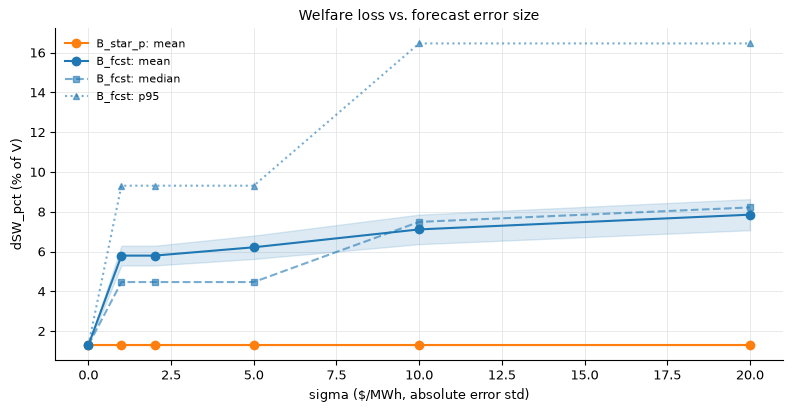

In [33]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for family, style in [("B_star_p", "C1"), ("B_fcst", "C0")]:
    sub = summary[summary.family == family]
    ax.plot(sub.sigma_abs, sub["mean"], style + "-o", label=f"{family}: mean")
    ax.fill_between(sub.sigma_abs, sub.ci95_lo, sub.ci95_hi, color=style, alpha=0.15)
    if family == "B_fcst":
        ax.plot(sub.sigma_abs, sub["median"], style + "--s", ms=4, alpha=0.6, label=f"{family}: median")
        ax.plot(sub.sigma_abs, sub["p95"], style + ":^", ms=4, alpha=0.6, label=f"{family}: p95")
ax.set_xlabel("sigma ($/MWh, absolute error std)"); ax.set_ylabel("dSW_pct (% of V)")
ax.set_title("Welfare loss vs. forecast error size")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()


**What this shows:**

- `B_star_p` is *exactly* constant across sigma -- correct by construction, since it never uses the forecast;
  it's the pure "quantity-information loss" baseline (`metrics.decompose`'s `quantity_part`). At `lambda*` the
  battery is indifferent between several plans; the throughput tie-breaker (`KAPPA`) picks the one that also
  runs the 00-04h -> 04-08h cycle, so this baseline is **1.30% of V** (6.32% with the LP solver's arbitrary
  vertex, `KAPPA = 0`).
- `B_fcst`: with any error at all the mean loss jumps to about 6% of V at sigma = 1 and rises to about 8% at
  sigma = 20. The tie-breaker plays no part there (it changed the plan in 0 of the 750 stage-0 draws): the
  forecast error breaks every tie by itself, in a random direction. **Being nearly indifferent costs as much as
  being exactly indifferent.**
- With common random numbers the sigma comparison is paired (next two cells): most draws keep the *same* loss at
  every sigma -- the error's *shape* decides the battery's plan, its size rarely does -- and in almost every
  draw the loss never decreases as sigma grows. The paired confidence intervals are 2-3 times narrower than
  the per-setting ones, so even the 2 -> 5 $/MWh step is resolved.
- The losses take only a few discrete values (about 2.2, 2.8, 3.1, 8.7, 9.3, 16.5% of V) -- the signature of
  the near-ties in this small case. A larger, better-conditioned stage-1 system, or perturbing block costs by a
  few cents (`CLAUDE.md` section 7), is still needed before reading a smooth sigma-vs-loss curve into it.
- **Rare load shedding remains** at large sigma: when the floor clips the forecast to 0 in most intervals, the
  battery is indifferent *when* to charge, may pick an interval where the market lets it buy only part of its
  plan, and runs empty in the evening peak. Throughput does not break a timing tie.

**Before the price floor** the same table showed means of 25-32% of V, flat in sigma, with p95 near 100%:
about 1 draw in 5 shed load because a negative forecast in the free intervals stopped the battery from charging
(Section 7.3). That was an artifact of predicting prices this market cannot produce.


In [34]:
fc_means = summary[summary.family == "B_fcst"].set_index("sigma_abs")["mean"]
d_all = fc_means.diff().dropna()
d_pos = fc_means[fc_means.index > 0].diff().dropna()
print("B_fcst mean dSW_pct by sigma:")
print(fc_means.round(2).to_string())
print(f"\nmonotone non-decreasing from sigma = 0: {bool((d_all >= -1e-9).all())}")
print(f"monotone non-decreasing from sigma = 1: {bool((d_pos >= -1e-9).all())}")
print("(experiments.md 5's check on the means; the paired, draw-by-draw version follows.)")

B_fcst mean dSW_pct by sigma:
sigma_abs
0.0     1.30
1.0     5.80
2.0     5.80
5.0     6.22
10.0    7.11
20.0    7.85

monotone non-decreasing from sigma = 0: True
monotone non-decreasing from sigma = 1: True
(experiments.md 5's check on the means; the paired, draw-by-draw version follows.)


In [35]:
# Draw-by-draw (paired) comparison of neighbouring sigma values -- possible because every setting uses the
# same error shapes (common random numbers). diff = loss at the larger sigma minus loss at the smaller one.
fc = stoch_df[stoch_df.family == "B_fcst"]
sigmas = sorted(s for s in fc.sigma_abs.unique() if s > 0)
rows = []
for s_a, s_b in zip(sigmas, sigmas[1:]):
    a, b = fc[fc.sigma_abs == s_a], fc[fc.sigma_abs == s_b]
    r = metrics.paired_difference(a, b, "dSW_pct")
    hw_unpaired = 1.96 * np.sqrt(a.dSW_pct.var() / len(a) + b.dSW_pct.var() / len(b))
    rows.append(dict(step=f"{s_a:g} -> {s_b:g}", mean_diff=r["mean"], ci95_lo=r["ci95_lo"], ci95_hi=r["ci95_hi"],
                     half_width_paired=r["ci95_hi"] - r["mean"], half_width_unpaired=hw_unpaired,
                     share_not_lower=r["share_b_ge_a"]))
display(pd.DataFrame(rows).round(2))
paths = np.array([fc[fc.sigma_abs == s].sort_values("draw").dSW_pct.to_numpy() for s in sigmas]).T
print(f"draws whose loss never decreases as sigma grows: {np.all(np.diff(paths, axis=1) >= -1e-9, axis=1).sum()} / {len(paths)}")
print(f"draws with the same loss at every sigma:         {np.all(np.abs(np.diff(paths, axis=1)) < 1e-9, axis=1).sum()} / {len(paths)}")


,step,mean_diff,ci95_lo,ci95_hi,half_width_paired,half_width_unpaired,share_not_lower
0,1 -> 2,0.00,0.00,0.00,0.00,0.70,1.00
1,2 -> 5,0.42,0.13,0.70,0.29,0.77,0.99
2,5 -> 10,0.90,0.53,1.27,0.37,0.95,1.00
3,10 -> 20,0.74,0.39,1.09,0.35,1.08,0.99


draws whose loss never decreases as sigma grows: 146 / 150
draws with the same loss at every sigma:         99 / 150


## 10. No simultaneous charge and discharge

Checked for every family at zero forecast error -- `experiments.md` section 4.1's
requirement, inherited from the equivalence note's arbitrage argument.

In [36]:
for name, b, full_cap in [
    ("B_star", bid_star, False),
    ("B_star_p", bid_star_p, False),
    ("B_priv", bid_priv, True),
]:
    blocks = bids.quantity_blocks(b, S, delta=0.01, full_capacity=full_cap)
    res = market.clear_cd(case, [blocks], voll=1000.0)
    sim = (res.p_da[0] > 1e-6) & (res.g_da[0] > 1e-6)
    print(f"{name:10s}: simultaneous charge+discharge = {bool(sim.any())}")


B_star    : simultaneous charge+discharge = False
B_star_p  : simultaneous charge+discharge = False
B_priv    : simultaneous charge+discharge = False


## 11. Summary and next step

**Passed** (structural gate, `experiments.md` section 5):
- `B_star` reproduces the benchmark dispatch exactly and gives `dSW = 0` to floating-
  point precision.
- `dSW >= -1e-6` holds for every setting and draw tested (no design can beat the
  benchmark it's measured against).
- No simultaneous charge/discharge in any family.
- The forecast model's own sampling statistics (unit variance, lag-1 autocorrelation
  `~rho`, cross-ESS correlation `~omega`) match specification, and `lambda_hat` never falls below the
  price floor (`tests/test_forecasts.py`).
- `k=0` (`sigma=0`) reproduces `B_star_p` exactly for `B_fcst` (`tests/test_bids.py`).

**Not verified** (and cannot be, without the missing files -- see the caveat at the
top): the specific published pilot numbers (11.1% of V, \$875, V=\$7,866.6/day, the
`B_priv` figures at 74.5/175.4/579.0%, 793.6 MWh undeliverable).

**New findings worth carrying into stage 1's design:**
1. This `day_case`'s storage value `V` is reliability-dominated (a genuine supply
   shortfall at hour 5 without the battery), not a pure arbitrage value -- worth having
   a second, non-reliability-constrained case to separate the two effects.
2. `B_priv` at `psi=0` gives exactly `dSW=0` here because of a binding-SOC-bound
   coincidence specific to this system (Section 8) -- don't assume this generalises.
3. **Negative price forecasts drove the earlier heavy-tailed, flat result.** Without a floor, 1 draw in 5 shed
   load at every sigma (a negative forecast in the zero-price intervals stopped the battery from charging).
   With `lambda_hat >= 0` (now the default, `ErrorModel.price_floor`) no draw sheds load and the mean loss rises
   at large sigma (flat within Monte Carlo noise up to sigma = 5 $/MWh, clearly higher at 10 and 20). For a market
   that does clear below zero, set the floor to that market's minimum.
4. **Exact ties at sigma = 0 are now broken towards the most active plan** (`BidRule.tie_break_reward`): the
   quantity-information baseline falls from 6.32% to 1.30% of V, and nothing changes once there is forecast
   error. The jump from 1.3% (sigma = 0) to about 6% (sigma = 1) shows that *near*-ties are the real problem.
   The losses still take a few discrete values; perturb block marginal costs (`experiments.md` section 7) or
   move to a larger stage-1 system before reading a smooth trend into it.
5. Why the error values are what they are (literature anchors for sigma, data anchor for rho, the floor):
   `docs/model_structure.pdf`, Section 6.

**Next step**: per `experiments.md` section 7, stage 1 only proceeds after this gate is
reviewed and a smoke test (2 settings x 5 draws, timed) is run and confirmed -- not
automatically from here. `results/stage0/` holds the run with the price floor, the tie-breaker and common
random numbers (stable seeds: the notebook and the CSVs give identical numbers in any session); the earlier
run is kept in `results/stage0_pre_tiebreak/`.